# Etapa 2 — Preparação dos Dados e Modelagem

Cada pessoa trabalha na sua seção abaixo. A Pessoa 4 integra tudo no final.

## Pessoa 1 — Limpeza e base comum

**Entrega:** função `limpar(df)`, função `avaliar(pipeline)` e a primeira linha da tabela comparativa.

- Tratar redundantes e inconsistentes: padronizar texto, valores impossíveis → ausentes, remover duplicatas e linhas contraditórias
- Remover colunas copiadas, a constante e as de vazamento
- Montar a função de avaliação usada por todos
- Rodar o modelo base com e sem `score_ids_legado`

### Limpeza dos dados

Nesta parte da Etapa 2 eu deixo a base limpa para o resto do grupo usar. Parti dos problemas que a análise exploratória da Etapa 1 encontrou (texto com grafias diferentes, valores impossíveis, colunas repetidas ou com vazamento, linhas duplicadas e contraditórias) e apliquei só regras fixas, que não aprendem nada dos dados.

Ficou de fora de propósito: imputar os ausentes, codificar os textos e normalizar os números. Isso é com as outras pessoas, dentro do pipeline de cada uma, para o ajuste ser feito só com o treino de cada fold.

As regras ficam no arquivo `limpeza.py`, na função `limpar(df, eh_treino)`. Aqui eu uso os passos dela um por um para mostrar o efeito de cada um, e no final confiro que a função inteira dá o mesmo resultado.

### 0. Leitura dos dados

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import limpeza as L   # as regras de limpeza ficam em limpeza.py

pd.set_option("display.max_columns", 60)
AZUL, LARANJA, CINZA = "#2a6fdb", "#d95f02", "#8a8a8a"

PASTA = Path("BANCO_DE_DADOS")
treino = pd.read_csv(PASTA / "treino.csv")
teste = pd.read_csv(PASTA / "teste_sem_rotulo.csv")
ALVO = "class"

print("treino:", treino.shape, "| teste:", teste.shape)

treino: (69833, 50) | teste: (24333, 50)


### 1. Padronizar o texto

`protocol_type` e `service` ficam sem espaços nas pontas e em minúsculas; `flag` fica sem espaços e em maiúsculas (é assim que ela aparece na maioria das linhas). Sem isso, `tcp` e `TCP` virariam categorias diferentes na hora de codificar. Conto quantas linhas mudaram.

In [2]:
# passo 1 da limpeza, nos dois arquivos
tr1 = L.padronizar_texto(treino)
te1 = L.padronizar_texto(teste)

# uma linha "mudou" se o valor ficou diferente do original (ausente continua ausente)
def mudou(antes, depois, cols):
    return antes[cols].ne(depois[cols]) & antes[cols].notna()

cols_texto = L.TEXTO_MINUSCULA + L.TEXTO_MAIUSCULA
m_tr, m_te = mudou(treino, tr1, cols_texto), mudou(teste, te1, cols_texto)

passo1 = pd.DataFrame({"treino": m_tr.sum(), "teste": m_te.sum()})
passo1.loc["linhas com alguma mudança"] = [m_tr.any(axis=1).sum(), m_te.any(axis=1).sum()]
display(passo1)

# conferindo: sobra uma grafia só por valor
print({c: tr1[c].nunique() for c in cols_texto})

,treino,teste
protocol_type,1455,0
service,1531,100
flag,1340,0
linhas com alguma mudança,4235,100


{'protocol_type': 3, 'service': 67, 'flag': 11}


**Conclusão do passo 1**

- No treino mudaram 4.235 linhas (`protocol_type` 1.455, `flag` 1.340 e `service` 1.531). Depois disso sobram só 3 protocolos, 11 flags e 67 serviços, sem grafias repetidas.
- No teste mudaram 100 linhas, todas em `service`. Não são erros de digitação: são serviços que já vêm em maiúsculas (`IRC`, `X11` e `Z39_50`), e a regra os deixa iguais aos do treino. Sem isso eles não casariam com as categorias do treino.

### 2. Valores impossíveis viram ausentes

Pela definição dos atributos, não faz sentido ter `duration`, `src_bytes` ou `dst_bytes` negativos, taxas (`*_rate`) acima de 1, `count` e `srv_count` acima de 511, ou `dst_host_count` e `dst_host_srv_count` acima de 255. Como os valores errados não seguem um fator de escala único (a Etapa 1 viu 1,5, 2, 5, 10 e até 512.000), não dá para "consertar": transformo em `NaN` e deixo a imputação para o pipeline.

In [3]:
tr2 = L.impossiveis_para_nan(tr1)
te2 = L.impossiveis_para_nan(te1)

# valores que viraram NaN = ausentes depois - ausentes antes, coluna por coluna
novos_tr = tr2.isna().sum() - tr1.isna().sum()
novos_te = te2.isna().sum() - te1.isna().sum()
passo2 = pd.DataFrame({"treino": novos_tr, "teste": novos_te}).fillna(0).astype(int)
passo2 = passo2[(passo2 > 0).any(axis=1)].sort_values("treino", ascending=False)
display(passo2)

# linhas afetadas = linhas que ganharam pelo menos um NaN novo
lin_tr = (tr2.isna() & tr1.notna()).any(axis=1).sum()
lin_te = (te2.isna() & te1.notna()).any(axis=1).sum()
print(f"Valores trocados por NaN: treino {passo2['treino'].sum()} | teste {passo2['teste'].sum()}")
print(f"Linhas afetadas: treino {lin_tr} | teste {lin_te}")

,treino,teste
dst_host_count,912,0
dst_host_srv_diff_host_rate,739,0
dst_host_srv_rerror_rate,714,0
rerror_rate,683,0
dst_host_same_srv_rate,670,0
dst_host_diff_srv_rate,623,0
srv_count,507,0
count,464,0
duration,358,0
src_bytes,189,0


Valores trocados por NaN: treino 5859 | teste 0
Linhas afetadas: treino 5650 | teste 0


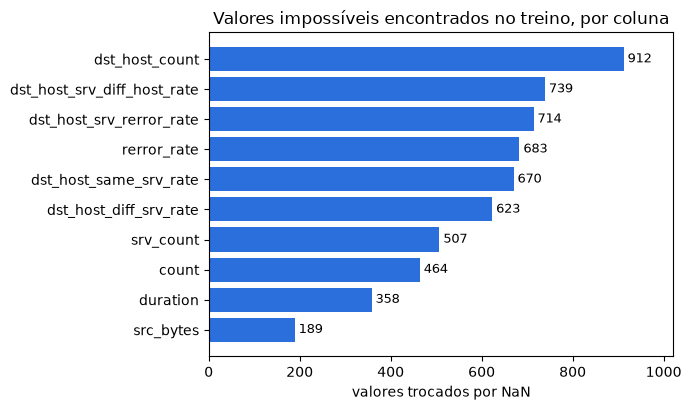

In [4]:
# gráfico 1: onde estavam os valores impossíveis (só o treino tem)
dados = passo2["treino"].iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(dados.index, dados.values, color=AZUL)
for i, v in enumerate(dados.values):   # escreve o número no fim de cada barra
    ax.text(v, i, f" {v}", va="center", fontsize=9)
ax.set_xlim(0, dados.max() * 1.12)
ax.set_xlabel("valores trocados por NaN")
ax.set_title("Valores impossíveis encontrados no treino, por coluna")
plt.tight_layout(); plt.show()

**Conclusão do passo 2**

- 5.859 valores do treino viraram `NaN`, em 5.650 linhas. O teste não tem nenhum valor impossível (os 18 que a Etapa 1 achou no teste eram todos do `su_attempted`, tratado no passo 3).
- Os maiores grupos são `dst_host_count` (912) e as taxas acima de 1, entre 623 e 739 em cada uma das cinco.
- Esses `NaN` se somam aos que já existiam, então o pipeline vai ter mais ausentes para imputar do que a Etapa 1 mostrou.

### 3. `su_attempted = 2` vira 1

Essa coluna deveria ser só 0 ou 1. O valor 2 aparece no treino e no teste, na mesma proporção (a Etapa 1 viu cerca de 0,07% nos dois), então não parece erro colocado só no treino. Tratei como "houve tentativa" e juntei com o 1.

In [5]:
tr3 = L.corrigir_su_attempted(tr2)
te3 = L.corrigir_su_attempted(te2)

print("treino antes:", treino["su_attempted"].value_counts(dropna=False).sort_index().to_dict())
print("treino depois:", tr3["su_attempted"].value_counts(dropna=False).sort_index().to_dict())
print("teste antes:", teste["su_attempted"].value_counts(dropna=False).sort_index().to_dict())
print("teste depois:", te3["su_attempted"].value_counts(dropna=False).sort_index().to_dict())

treino antes: {0.0: 66462, 1.0: 16, 2.0: 49, nan: 3306}
treino depois: {0.0: 66462, 1.0: 65, nan: 3306}
teste antes: {0.0: 23123, 1.0: 9, 2.0: 18, nan: 1183}
teste depois: {0.0: 23123, 1.0: 27, nan: 1183}


**Conclusão do passo 3**

- 49 linhas do treino e 18 do teste tinham `su_attempted = 2`. Agora a coluna só tem 0, 1 ou ausente nas duas bases (os ausentes não foram mexidos).

### 4. Remover colunas

Saem 8 colunas, todas por motivos que a Etapa 1 mostrou:

- **cópias** de colunas que já existem: `src_bytes_kb`, `dst_bytes_kb`, `total_bytes`, `same_srv_pct` e `protocolo_cod`;
- **constante**: `num_outbound_cmds` (um valor só, não ajuda em nada);
- **vazamento**: `tempo_resposta_analista_min` e `tipo_alerta_soc`, que só existem depois que um analista olha a conexão e entregam a classe.

> **Aviso para o grupo:** `score_ids_legado` foi **mantida**. Não sabemos de onde vem essa nota (se vem de um sistema em tempo real ou se foi gerada depois), então o grupo ainda vai decidir se usa. Quem for modelar deve testar com e sem ela.

In [6]:
tr4 = L.remover_colunas(tr3)
te4 = L.remover_colunas(te3)

print("colunas removidas:", L.REMOVER)
print(f"treino: {tr3.shape[1]} -> {tr4.shape[1]} colunas | teste: {te3.shape[1]} -> {te4.shape[1]} colunas")
print("score_ids_legado continua na base:", "score_ids_legado" in tr4.columns and "score_ids_legado" in te4.columns)

colunas removidas: ['src_bytes_kb', 'dst_bytes_kb', 'total_bytes', 'same_srv_pct', 'protocolo_cod', 'num_outbound_cmds', 'tempo_resposta_analista_min', 'tipo_alerta_soc']
treino: 50 -> 42 colunas | teste: 50 -> 42 colunas
score_ids_legado continua na base: True


**Conclusão do passo 4**

- Cada base ficou com 42 colunas: o treino com `class` e o teste com `id`, e as outras 41 iguais nos dois.

### 5. Duplicatas e linhas contraditórias (só no treino)

Esse passo só vale para o treino, depois dos passos anteriores e **nesta ordem**:

1. tiro as linhas exatamente iguais (mesmos atributos e mesma classe), ficando com uma cópia de cada;
2. depois, o que sobrar de linhas com atributos idênticos e classes diferentes eu tiro **inteiro**: não dá para saber qual rótulo está certo, então nenhuma das linhas do grupo fica.

Se a ordem fosse a contrária, as cópias de uma mesma linha contariam como "classes iguais" e o grupo poderia passar despercebido ou ser contado errado. Também não faço isso no teste, porque lá não se pode perder linha.

In [7]:
n0 = len(tr4)
anom0 = (tr4[ALVO] == "anomaly").mean() * 100

tr5a = L.remover_duplicatas(tr4)
n1 = len(tr5a)
anom1 = (tr5a[ALVO] == "anomaly").mean() * 100

tr5 = L.remover_contraditorias(tr5a)
n2 = len(tr5)
anom2 = (tr5[ALVO] == "anomaly").mean() * 100

# quantos grupos contraditórios foram tirados (só pra mostrar; a função já fez o trabalho)
atrib = [c for c in tr5a.columns if c != ALVO]
tam_grupo = tr5a.groupby(atrib, dropna=False)[ALVO].transform("size")
n_grupos = tr5a[tam_grupo > 1].groupby(atrib, dropna=False).ngroups

etapas = pd.DataFrame({
    "linhas": [n0, n1, n2],
    "anomalias": [(tr4[ALVO] == "anomaly").sum(), (tr5a[ALVO] == "anomaly").sum(), (tr5[ALVO] == "anomaly").sum()],
    "% anomalias": [anom0, anom1, anom2],
}, index=["antes", "sem duplicatas exatas", "sem grupos contraditórios"])
etapas["normais"] = etapas["linhas"] - etapas["anomalias"]
display(etapas[["linhas", "normais", "anomalias", "% anomalias"]].round(2))

print(f"Duplicatas removidas: {n0 - n1}")
print(f"Linhas contraditórias removidas: {n1 - n2} (em {n_grupos} grupos)")
print(f"Proporção de anomalias: {anom0:.2f}% -> {anom2:.2f}%")

,linhas,normais,anomalias,% anomalias
antes,69833,65754,4079,5.84
sem duplicatas exatas,58478,54959,3519,6.02
sem grupos contraditórios,55074,53257,1817,3.30


Duplicatas removidas: 11355
Linhas contraditórias removidas: 3404 (em 1702 grupos)
Proporção de anomalias: 5.84% -> 3.30%


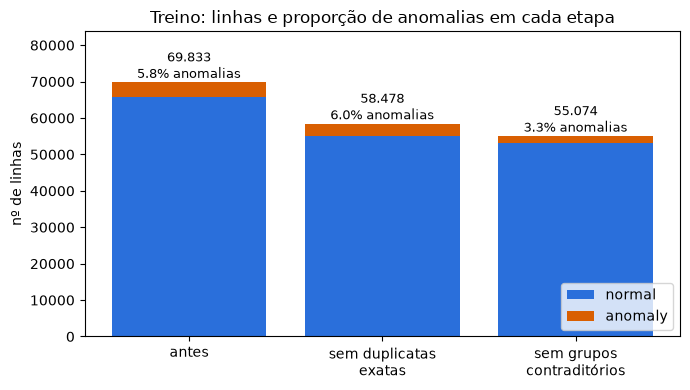

In [8]:
# gráfico 2: linhas do treino em cada etapa, com a % de anomalias
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(3)
ax.bar(x, etapas["normais"], color=AZUL, label="normal")
ax.bar(x, etapas["anomalias"], bottom=etapas["normais"], color=LARANJA, label="anomaly")
for i, (n, p) in enumerate(zip(etapas["linhas"], etapas["% anomalias"])):
    ax.text(i, n, f"{n:,}\n{p:.1f}% anomalias".replace(",", "."), ha="center", va="bottom", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(["antes", "sem duplicatas\nexatas", "sem grupos\ncontraditórios"])
ax.set_ylim(0, etapas["linhas"].max() * 1.2)
ax.set_ylabel("nº de linhas")
ax.set_title("Treino: linhas e proporção de anomalias em cada etapa")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Conclusão do passo 5**

- Saíram 11.355 duplicatas exatas (o treino foi de 69.833 para 58.478 linhas). A proporção de anomalias subiu de 5,84% para 6,02%.
- Depois saíram 3.404 linhas de 1.702 grupos contraditórios, o que deixa o treino com 55.074 linhas.
- **Atenção:** cada grupo tinha exatamente uma linha normal e uma anomalia. Então saíram 1.702 de cada classe, e as anomalias caíram de 3.519 para 1.817. A proporção final de anomalias é de **3,30%** (cerca de 29 normais para cada anomalia), bem mais desbalanceado do que os 5,8% originais. O grupo precisa saber disso ao escolher o balanceamento.

### 6. O teste

O teste passa só pelos passos 1 a 4 e **nunca perde linha**. A coluna `id` fica, porque é ela que identifica cada linha na submissão. Abaixo aplico a função completa `limpar()` nos dois arquivos e confiro se o resultado é igual ao que fiz passo a passo.

In [9]:
# a função completa, do jeito que o grupo vai usar
treino_limpo = L.limpar(treino, eh_treino=True)
teste_limpo = L.limpar(teste, eh_treino=False)

# tem que dar exatamente o mesmo que o passo a passo
print("treino igual ao passo a passo:", treino_limpo.equals(tr5))
print("teste igual ao passo a passo:", teste_limpo.equals(te4))
print("treino_limpo:", treino_limpo.shape, "| teste_limpo:", teste_limpo.shape)

treino igual ao passo a passo: True
teste igual ao passo a passo: True
treino_limpo: (55074, 42) | teste_limpo: (24333, 42)


### 7. Salvando e conferindo

Salvo os dois arquivos limpos em `BANCO_DE_DADOS/`. Depois **leio de volta os CSVs** e faço as conferências em cima deles, que é o que o grupo vai usar de verdade: linhas do teste, valores impossíveis, colunas do treino e do teste, `id` e duplicatas.

In [10]:
treino_limpo.to_csv(PASTA / "treino_limpo.csv", index=False)
teste_limpo.to_csv(PASTA / "teste_limpo.csv", index=False)

# leitura de volta, pra conferir os arquivos e não só a memória
tr_f = pd.read_csv(PASTA / "treino_limpo.csv")
te_f = pd.read_csv(PASTA / "teste_limpo.csv")

# conta valores impossíveis com as regras escritas de novo aqui (sem usar o limpeza.py)
def impossiveis(df):
    taxas = [c for c in df.columns if c.endswith("_rate")]
    out = {}
    for c in ["duration", "src_bytes", "dst_bytes"]:
        out[f"{c} < 0"] = (df[c] < 0).sum()
    out["*_rate > 1"] = (df[taxas] > 1).sum().sum()
    out["count ou srv_count > 511"] = (df[["count", "srv_count"]] > 511).sum().sum()
    out["dst_host_count ou dst_host_srv_count > 255"] = (df[["dst_host_count", "dst_host_srv_count"]] > 255).sum().sum()
    out["su_attempted fora de {0, 1}"] = (df["su_attempted"].notna() & ~df["su_attempted"].isin([0, 1])).sum()
    return pd.Series(out)

imp = pd.DataFrame({"treino_limpo": impossiveis(tr_f), "teste_limpo": impossiveis(te_f)})
display(imp)

cols_tr = [c for c in tr_f.columns if c != ALVO]
cols_te = [c for c in te_f.columns if c != "id"]
atributos = tr_f.drop(columns=ALVO)
# linhas com atributos iguais, mas qualquer classe (se não sobrou duplicata exata, seriam contraditórias)
iguais = atributos.duplicated(keep=False)

def texto_ok(df):
    ok = True
    for c in L.TEXTO_MINUSCULA:
        ok &= (df[c].dropna() == df[c].dropna().str.strip().str.lower()).all()
    for c in L.TEXTO_MAIUSCULA:
        ok &= (df[c].dropna() == df[c].dropna().str.strip().str.upper()).all()
    return bool(ok)

conferencias = {
    "teste com 24.333 linhas": len(te_f) == 24333,
    "teste com as mesmas linhas, na mesma ordem (id igual ao original)": te_f["id"].equals(teste["id"]),
    "nenhum valor impossível (treino e teste)": int(imp.to_numpy().sum()) == 0,
    "colunas do treino = colunas do teste (fora class e id)": cols_tr == cols_te,
    "class só no treino e id só no teste": ALVO in tr_f.columns and ALVO not in te_f.columns and "id" in te_f.columns and "id" not in tr_f.columns,
    "treino sem duplicatas exatas": not tr_f.duplicated().any(),
    "treino sem linhas iguais (nem com classes diferentes)": not iguais.any(),
    "nenhuma coluna removida sobrou": not set(L.REMOVER) & (set(tr_f.columns) | set(te_f.columns)),
    "score_ids_legado mantida": "score_ids_legado" in tr_f.columns and "score_ids_legado" in te_f.columns,
    "texto padronizado (treino e teste)": texto_ok(tr_f) and texto_ok(te_f),
}
for nome, ok in conferencias.items():
    print("OK  " if ok else "ERRO", nome)
assert all(conferencias.values()), "alguma conferência falhou"

print(f"\ncolunas do treino ({tr_f.shape[1]}):", list(tr_f.columns))

,treino_limpo,teste_limpo
duration < 0,0,0
src_bytes < 0,0,0
dst_bytes < 0,0,0
*_rate > 1,0,0
count ou srv_count > 511,0,0
dst_host_count ou dst_host_srv_count > 255,0,0
"su_attempted fora de {0, 1}",0,0


OK   teste com 24.333 linhas
OK   teste com as mesmas linhas, na mesma ordem (id igual ao original)
OK   nenhum valor impossível (treino e teste)
OK   colunas do treino = colunas do teste (fora class e id)
OK   class só no treino e id só no teste
OK   treino sem duplicatas exatas
OK   treino sem linhas iguais (nem com classes diferentes)
OK   nenhuma coluna removida sobrou
OK   score_ids_legado mantida
OK   texto padronizado (treino e teste)

colunas do treino (42): ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_dif

**Conclusão do passo 7**

- O teste tem as mesmas 24.333 linhas, com o `id` igual ao original e na mesma ordem.
- Não sobrou nenhum valor impossível no treino nem no teste.
- As 41 colunas de atributos são iguais nos dois arquivos, na mesma ordem. Sobrou também uma coluna de cada lado: `class` no treino e `id` no teste.
- O treino não tem mais nenhuma linha repetida.

### 8. Diagnóstico final

Resumo de tudo que foi feito, quantas linhas ou colunas cada passo afetou e o motivo. Os números saem das variáveis do notebook, não foram digitados.

In [11]:
fmt = lambda n: f"{int(n):,}".replace(",", ".")

# números de cada passo (cada um calculado nas células acima)
diag = pd.DataFrame([
    ["1. Padronizar texto (strip + minúsculas/maiúsculas)",
     f"{fmt(m_tr.any(axis=1).sum())} linhas", f"{fmt(m_te.any(axis=1).sum())} linhas",
     "O mesmo valor aparecia com grafias diferentes (TCP, espaço no final do service) e viraria categorias separadas."],
    ["2. Valores impossíveis -> NaN",
     f"{fmt(lin_tr)} linhas ({fmt(passo2['treino'].sum())} valores)", f"{fmt(lin_te)} linhas ({fmt(passo2['teste'].sum())} valores)",
     "Negativos e fora dos limites não existem pela definição dos atributos. Viram ausentes para o pipeline imputar."],
    ["3. su_attempted 2 -> 1",
     f"{fmt((tr2['su_attempted'] == 2).sum())} linhas", f"{fmt((te2['su_attempted'] == 2).sum())} linhas",
     "A coluna só deveria ter 0 ou 1; o 2 aparece nas duas bases na mesma proporção."],
    ["4. Remover colunas (cópias, constante, vazamento)",
     f"{len(L.REMOVER)} colunas", f"{len(L.REMOVER)} colunas",
     "Cópias e constante não acrescentam informação; as duas de vazamento só existem depois de um analista olhar a conexão. score_ids_legado foi mantida (grupo decide)."],
    ["5a. Remover duplicatas exatas (só treino)",
     f"{fmt(n0 - n1)} linhas", "0 (não se aplica)",
     "A mesma linha no treino e na validação deixa o resultado otimista; as cópias também tinham mais anomalias que o resto."],
    ["5b. Remover grupos contraditórios (só treino)",
     f"{fmt(n1 - n2)} linhas ({fmt(n_grupos)} grupos)", "0 (não se aplica)",
     "Atributos idênticos com classes diferentes são ruído de rótulo: nenhum modelo acerta os dois."],
    ["Resultado final",
     f"{fmt(len(treino))} -> {fmt(len(tr_f))} linhas; {treino.shape[1]} -> {tr_f.shape[1]} colunas; anomalias {(treino[ALVO] == 'anomaly').mean() * 100:.1f}% -> {(tr_f[ALVO] == 'anomaly').mean() * 100:.1f}%",
     f"{fmt(len(teste))} -> {fmt(len(te_f))} linhas (nenhuma perdida); {teste.shape[1]} -> {te_f.shape[1]} colunas",
     "Base comum para o grupo. Ainda faltam: imputar, codificar e normalizar (dentro do pipeline)."],
], columns=["o que foi feito", "treino", "teste", "por quê"])

with pd.option_context("display.max_colwidth", 200):
    display(diag.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal"}))

o que foi feito,treino,teste,por quê
1. Padronizar texto (strip + minúsculas/maiúsculas),4.235 linhas,100 linhas,"O mesmo valor aparecia com grafias diferentes (TCP, espaço no final do service) e viraria categorias separadas."
2. Valores impossíveis -> NaN,5.650 linhas (5.859 valores),0 linhas (0 valores),Negativos e fora dos limites não existem pela definição dos atributos. Viram ausentes para o pipeline imputar.
3. su_attempted 2 -> 1,49 linhas,18 linhas,A coluna só deveria ter 0 ou 1; o 2 aparece nas duas bases na mesma proporção.
"4. Remover colunas (cópias, constante, vazamento)",8 colunas,8 colunas,Cópias e constante não acrescentam informação; as duas de vazamento só existem depois de um analista olhar a conexão. score_ids_legado foi mantida (grupo decide).
5a. Remover duplicatas exatas (só treino),11.355 linhas,0 (não se aplica),A mesma linha no treino e na validação deixa o resultado otimista; as cópias também tinham mais anomalias que o resto.
5b. Remover grupos contraditórios (só treino),3.404 linhas (1.702 grupos),0 (não se aplica),Atributos idênticos com classes diferentes são ruído de rótulo: nenhum modelo acerta os dois.
Resultado final,69.833 -> 55.074 linhas; 50 -> 42 colunas; anomalias 5.8% -> 3.3%,24.333 -> 24.333 linhas (nenhuma perdida); 50 -> 42 colunas,"Base comum para o grupo. Ainda faltam: imputar, codificar e normalizar (dentro do pipeline)."


**Para quem for usar:** `from limpeza import limpar` e depois `limpar(df, eh_treino=True)` para o treino ou `limpar(df, eh_treino=False)` para o teste, ou então ler direto `treino_limpo.csv` e `teste_limpo.csv`. A base ainda tem ausentes, textos e escalas diferentes: imputar, codificar e normalizar entram no pipeline de cada um, ajustando só com o treino de cada fold. E lembrem que `score_ids_legado` ainda está em aberto.

**Ainda falta nesta seção:** a função `avaliar(pipeline)` e o modelo base com e sem `score_ids_legado`.

## Pessoa 2 — Ausentes e codificação

**Entrega:** comparação das técnicas com F1-macro e a justificativa.

- Imputação: mediana × outra estratégia
- Codificação dos categóricos, discutindo a alta cardinalidade de `service` (ex.: one-hot × codificação por frequência)

### Ausentes e codificação: como comparei

Nesta parte eu decido como preencher os valores ausentes e como transformar os atributos de texto em números. Parto da base limpa da Pessoa 1 (`treino_limpo.csv`), que ainda tem ausentes, inclusive os valores impossíveis que ela transformou em `NaN`.

- **Tudo dentro do `Pipeline`.** A imputação e a codificação ficam na função `montar_preprocessador()` do arquivo `ausentes_codificacao.py`. Como ela devolve um transformador do sklearn, a mediana, as frequências e as taxas por categoria são calculadas só com o treino de cada fold. A validação nunca entra no ajuste.
- **Métrica e validação.** F1-macro (a métrica do ranking) em 5 folds estratificados, repetidos 2 vezes: são 10 medidas por técnica. Todas as técnicas usam exatamente os mesmos folds, então além da média eu conto em quantos dos 10 folds cada técnica ganhou da referência. Diferença de milésimos na média pode ser sorte; ganhar em quase todos os folds, não.
- **Dois modelos fixos, sem ajuste:** regressão logística (linear, sente muito a codificação) e random forest (árvores). O modelo final ainda não foi escolhido, e uma técnica pode ajudar um modelo e atrapalhar o outro.
- **Uma coisa por vez.** Primeiro comparo a imputação, com a codificação fixa em one-hot. Depois comparo a codificação, com a imputação que ganhou.
- **O que não é meu e ficou fixo:** os números passam por um `StandardScaler` só para a regressão logística convergir (escalas são da Pessoa 3) e não há balanceamento (Pessoa 4). Por isso o F1 absoluto ainda vai mudar; aqui importa a diferença entre as técnicas.
- **`score_ids_legado` ficou de fora** (`USAR_SCORE = False`) até o grupo decidir. Ela pode ser vazamento e é tão forte que esconderia a diferença entre as técnicas.
- **`avaliar()` provisório.** O da Pessoa 1 ainda não saiu, então escrevi um com a mesma ideia. Quando o oficial sair, é só trocar e rodar de novo.

**Regra de escolha**, definida antes de rodar e aplicada pela função `escolher()`:

1. a técnica não pode ter média menor que a referência em nenhum dos dois modelos;
2. ela precisa ganhar da referência em pelo menos 8 dos 10 folds em pelo menos um modelo;
3. entre as que passam, fico com a de maior F1-macro na random forest, que é o modelo mais forte.

Se nenhuma passar, fico com a referência, que é a mais simples. A seção inteira leva uns 7 minutos para rodar.

In [12]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score

from ausentes_codificacao import montar_preprocessador, CATEGORICAS, COL_AUSENCIA_INFORMATIVA

warnings.filterwarnings("ignore", category=UserWarning)   # aviso de categoria desconhecida no one-hot
pd.set_option("display.max_columns", 60)
AZUL, LARANJA, CINZA = "#2a6fdb", "#d95f02", "#8a8a8a"

PASTA = Path("BANCO_DE_DADOS")
ALVO = "class"
tr_limpo = pd.read_csv(PASTA / "treino_limpo.csv")
te_limpo = pd.read_csv(PASTA / "teste_limpo.csv")

# score_ids_legado fica de fora até o grupo decidir (ver texto acima)
USAR_SCORE = False
fora = [ALVO] + ([] if USAR_SCORE else ["score_ids_legado"])
X = tr_limpo.drop(columns=fora)
y = (tr_limpo[ALVO] == "anomaly").astype(int)   # 1 = anomaly
X_teste = te_limpo[X.columns]

# os dois modelos fixos das comparações: um linear e um de árvores
MODELOS = {
    "Regressão logística": LogisticRegression(max_iter=2000),
    "Random forest": RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
}

# 5 folds estratificados, repetidos 2 vezes = 10 medidas por técnica, sempre nos mesmos folds
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42)


def avaliar(pipeline, X=X, y=y):
    """F1-macro em cada um dos 10 folds (versão provisória até sair o avaliar() da Pessoa 1)."""
    return cross_val_score(pipeline, X, y, cv=CV, scoring="f1_macro", n_jobs=1)


def comparar(tecnicas, referencia):
    """Roda cada técnica com cada modelo. tecnicas = {nome: kwargs do montar_preprocessador}.
    Compara com a referência fold a fold (os folds são os mesmos para todas)."""
    linhas, folds = [], {}
    for modelo_nome, modelo in MODELOS.items():
        for nome, kwargs in tecnicas.items():
            pipe = Pipeline([("pre", montar_preprocessador(**kwargs)), ("modelo", modelo)])
            t0 = time.time()
            notas = avaliar(pipe)
            folds[(modelo_nome, nome)] = notas
            linhas.append({"modelo": modelo_nome, "técnica": nome, "F1-macro": notas.mean(),
                           "desvio": notas.std(), "tempo (s)": time.time() - t0})
    res = pd.DataFrame(linhas)
    # diferença pareada: mesma divisão de folds, então dá pra comparar fold com fold
    dif = [folds[(m, t)] - folds[(m, referencia)] for m, t in zip(res["modelo"], res["técnica"])]
    res["dif. p/ referência"] = [d.mean() for d in dif]
    res["folds em que ganhou"] = [f"{(d > 0).sum()}/{len(d)}" for d in dif]
    return res, folds


def escolher(res, referencia, min_folds=8):
    """Regra de escolha (a mesma para imputação e codificação):
    1) a técnica não pode ter média menor que a referência em nenhum dos dois modelos;
    2) tem que ganhar da referência em pelo menos `min_folds` dos 10 folds em pelo menos um modelo;
    3) entre as que passam, fica a de maior F1-macro na random forest (o modelo mais forte).
    Se nenhuma passar, fica a referência, que é a mais simples."""
    tab = res.pivot(index="técnica", columns="modelo", values="dif. p/ referência")
    ganhos = res.assign(g=res["folds em que ganhou"].str.split("/").str[0].astype(int)) \
                .pivot(index="técnica", columns="modelo", values="g")
    rf = res[res["modelo"] == "Random forest"].set_index("técnica")["F1-macro"]
    tab["não piora nenhum"] = (tab[list(MODELOS)] >= 0).all(axis=1)
    tab[f"ganha em ≥{min_folds}/10 em algum"] = (ganhos[list(MODELOS)] >= min_folds).any(axis=1)
    tab["passa"] = tab["não piora nenhum"] & tab[f"ganha em ≥{min_folds}/10 em algum"]
    passam = [t for t in tab.index if t != referencia and bool(tab.loc[t, "passa"])]
    tab = tab.astype({c: object for c in ["não piora nenhum", f"ganha em ≥{min_folds}/10 em algum", "passa"]})
    tab.loc[referencia, ["não piora nenhum", f"ganha em ≥{min_folds}/10 em algum", "passa"]] = "—"
    tab = tab.loc[res["técnica"].unique()]
    escolhida = max(passam, key=lambda t: rf[t]) if passam else referencia
    display(tab.rename(columns={m: f"dif. {m}" for m in MODELOS}).round(4))
    print("Escolhida:", escolhida)
    return escolhida


print("treino:", X.shape, "| teste:", X_teste.shape)
print("anomalias no treino:", f"{y.mean() * 100:.2f}%")
print("score_ids_legado nas comparações:", USAR_SCORE)

treino: (55074, 40) | teste: (24333, 40)
anomalias no treino: 3.30%
score_ids_legado nas comparações: False


### 1. Onde estão os ausentes

Antes de escolher a imputação, vejo quanto falta em cada coluna, no treino e no teste, e se a falta muda de uma classe para a outra. Se mudar, o fato de o valor estar ausente já diz algo sobre a classe, e vale testar uma coluna indicando a ausência.

In [13]:
aus = pd.DataFrame({
    "treino (%)": X.isna().mean() * 100,
    "teste (%)": X_teste.isna().mean() * 100,
    "normal (%)": X[y == 0].isna().mean() * 100,
    "anomaly (%)": X[y == 1].isna().mean() * 100,
})
aus = aus[aus["treino (%)"] > 0]
aus["anomaly - normal (p.p.)"] = aus["anomaly (%)"] - aus["normal (%)"]
aus = aus.sort_values("treino (%)", ascending=False)
display(aus.round(2))

cats_aus = [c for c in CATEGORICAS if c in aus.index]
print(f"Colunas com ausentes: {len(aus)} ({len(aus) - len(cats_aus)} numéricas e {len(cats_aus)} categóricas: {cats_aus})")
print(f"Linhas com pelo menos um ausente: treino {X.isna().any(axis=1).mean() * 100:.1f}% | teste {X_teste.isna().any(axis=1).mean() * 100:.1f}%")
print(f"Linhas que sobrariam se eu apagasse quem tem ausente: {(~X.isna().any(axis=1)).sum()} de {len(X)}")
maior = aus["anomaly - normal (p.p.)"].abs().idxmax()
print(f"Maior diferença entre as classes: {maior} ({aus.loc[maior, 'normal (%)']:.1f}% nas normais x {aus.loc[maior, 'anomaly (%)']:.1f}% nas anomalias)")

# quanto o "está ausente" dessa coluna separa as classes sozinho (0,5 = nada; 1 = perfeito)
auc_ind = roc_auc_score(y, X[COL_AUSENCIA_INFORMATIVA].isna())
print(f"AUC do indicador '{COL_AUSENCIA_INFORMATIVA} ausente' sozinho: {auc_ind:.3f}")

,treino (%),teste (%),normal (%),anomaly (%),anomaly - normal (p.p.)
src_bytes,40.22,40.52,40.27,38.69,-1.58
dst_host_srv_count,39.82,39.32,39.79,40.62,0.82
dst_host_serror_rate,30.01,30.23,29.42,47.39,17.97
dst_host_same_src_port_rate,28.05,28.14,28.12,26.03,-2.09
dst_host_count,6.98,5.41,6.97,7.21,0.24
serror_rate,6.81,6.70,6.80,7.32,0.52
service,6.34,6.28,6.33,6.77,0.44
srv_count,6.33,5.67,6.34,5.83,-0.51
rerror_rate,6.32,5.36,6.31,6.44,0.13
logged_in,6.06,5.93,6.04,6.55,0.50


Colunas com ausentes: 27 (25 numéricas e 2 categóricas: ['service', 'flag'])
Linhas com pelo menos um ausente: treino 94.2% | teste 93.7%
Linhas que sobrariam se eu apagasse quem tem ausente: 3178 de 55074
Maior diferença entre as classes: dst_host_serror_rate (29.4% nas normais x 47.4% nas anomalias)
AUC do indicador 'dst_host_serror_rate ausente' sozinho: 0.590


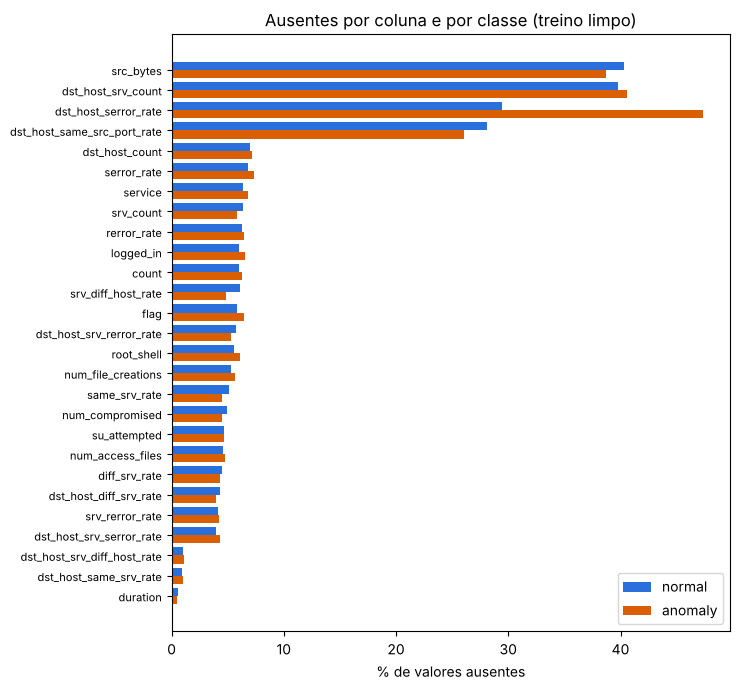

In [14]:
# gráfico 1: % de ausentes por coluna, separado por classe
d = aus.iloc[::-1]
pos = np.arange(len(d))
fig, ax = plt.subplots(figsize=(7.5, 7))
ax.barh(pos + 0.2, d["normal (%)"], height=0.4, color=AZUL, label="normal")
ax.barh(pos - 0.2, d["anomaly (%)"], height=0.4, color=LARANJA, label="anomaly")
ax.set_yticks(pos)
ax.set_yticklabels(d.index, fontsize=8)
ax.set_xlabel("% de valores ausentes")
ax.set_title("Ausentes por coluna e por classe (treino limpo)")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Conclusão do passo 1**

- 27 colunas têm ausentes: 25 numéricas e 2 de texto (`service` e `flag`). As que mais faltam são `src_bytes` (40,2%), `dst_host_srv_count` (39,8%), `dst_host_serror_rate` (30,0%) e `dst_host_same_src_port_rate` (28,1%). As outras ficam entre 0,5% e 7%.
- 94,2% das linhas do treino têm pelo menos um ausente. Se eu apagasse essas linhas, sobrariam 3.178 de 55.074, e no teste não dá para apagar nenhuma. Então a saída é imputar.
- As proporções são parecidas no treino e no teste. A exceção são `duration`, `dst_host_same_srv_rate` e `dst_host_srv_diff_host_rate`, que só têm ausentes no treino: esses ausentes vieram dos valores impossíveis que a Pessoa 1 transformou em `NaN`, e o teste não tinha nenhum.
- Em quase todas as colunas, a falta é igual nas duas classes (diferença de no máximo 2,1 pontos percentuais). A exceção é `dst_host_serror_rate`: falta em 29,4% das normais e em 47,4% das anomalias. Mesmo assim, o indicador "está ausente" dessa coluna, sozinho, separa pouco as classes (AUC de 0,59, em que 0,5 é não separar nada).

### 2. Imputação

Comparo seis formas de preencher os ausentes, todas com o `service` em one-hot:

- **mediana** (referência): não é puxada pelos valores extremos, e bytes e contagens são muito assimétricos;
- **média**: a alternativa simples, mas sofre com os extremos;
- **mediana + indicador de `dst_host_serror_rate`**: além de preencher, cria uma coluna 0/1 dizendo se o valor estava ausente, só na coluna em que a Etapa 1 viu a ausência ligada à classe;
- **mediana + indicadores em todas**: a mesma ideia, uma coluna 0/1 para cada atributo com ausente (`add_indicator=True`);
- **iterativa** (`IterativeImputer`): prevê cada coluna ausente a partir das outras, em rodadas. É a alternativa multivariada;
- **mediana + categoria "ausente" nos textos**: em vez de usar a moda, o `service` ou a `flag` ausente vira uma categoria própria.

Nos textos, a referência é a moda (o valor mais comum).

Também pensei no `KNNImputer`. Num teste com um fold, ele levou cerca de 40 segundos só para preencher as 11 mil linhas da validação; o treino de cada fold é 4 vezes maior, e isso se repetiria em 10 folds e 2 modelos. Deixei de fora pelo custo, e a iterativa já cobre a ideia de usar as outras colunas para preencher.

In [15]:
# codificação fixa (one-hot) para isolar o efeito da imputação
TEC_IMP = {
    "mediana (referência)":          dict(num="mediana", cat="moda", codificacao="onehot"),
    "média":                         dict(num="media", cat="moda", codificacao="onehot"),
    "mediana + indicador serror":    dict(num="mediana+indicador_serror", cat="moda", codificacao="onehot"),
    "mediana + indicadores (todas)": dict(num="mediana+indicadores", cat="moda", codificacao="onehot"),
    "iterativa (multivariada)":      dict(num="iterativa", cat="moda", codificacao="onehot"),
    "mediana + cat. 'ausente'":      dict(num="mediana", cat="constante", codificacao="onehot"),
}
res_imp, folds_imp = comparar(TEC_IMP, referencia="mediana (referência)")
display(res_imp.round(4))

,modelo,técnica,F1-macro,desvio,tempo (s),dif. p/ referência,folds em que ganhou
0,Regressão logística,mediana (referência),0.9302,0.0053,6.6147,0.0000,0/10
1,Regressão logística,média,0.9304,0.0059,5.6335,0.0001,4/10
2,Regressão logística,mediana + indicador serror,0.9296,0.0060,6.7146,-0.0007,3/10
3,Regressão logística,mediana + indicadores (todas),0.9300,0.0042,7.6346,-0.0002,5/10
4,Regressão logística,iterativa (multivariada),0.9322,0.0067,37.3074,0.0019,7/10
5,Regressão logística,mediana + cat. 'ausente',0.9332,0.0056,7.2262,0.0030,8/10
6,Random forest,mediana (referência),0.9728,0.0043,24.3344,0.0000,0/10
7,Random forest,média,0.9703,0.0050,22.5771,-0.0025,1/10
8,Random forest,mediana + indicador serror,0.9711,0.0048,23.7084,-0.0017,2/10
9,Random forest,mediana + indicadores (todas),0.9691,0.0059,24.7539,-0.0037,0/10


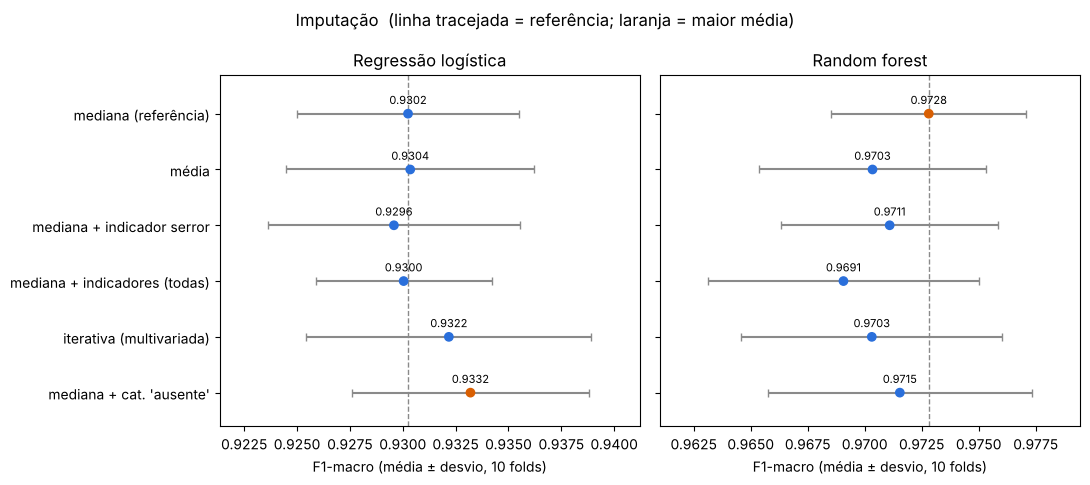

In [16]:
def grafico_comparacao(res, titulo):
    """Um painel por modelo: média do F1-macro nos 10 folds, com o desvio padrão."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 0.55 * res["técnica"].nunique() + 1.6), sharey=True)
    ordem = list(dict.fromkeys(res["técnica"]))[::-1]
    for ax, (modelo, r) in zip(axes, res.groupby("modelo", sort=False)):
        r = r.set_index("técnica").loc[ordem]
        ref = r.iloc[-1]["F1-macro"]   # a referência é a primeira técnica da lista
        melhor = r["F1-macro"].idxmax()
        cores = [LARANJA if t == melhor else AZUL for t in r.index]
        ax.errorbar(r["F1-macro"], np.arange(len(r)), xerr=r["desvio"], fmt="none", ecolor=CINZA, capsize=3)
        ax.scatter(r["F1-macro"], np.arange(len(r)), color=cores, zorder=3)
        ax.axvline(ref, color=CINZA, ls="--", lw=1)
        for i, v in enumerate(r["F1-macro"]):
            ax.annotate(f"{v:.4f}", (v, i), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
        ax.set_ylim(-0.6, len(r) - 0.3)   # espaço para o número da primeira linha
        ax.set_yticks(np.arange(len(r)))
        ax.set_yticklabels(r.index)
        ax.set_title(modelo)
        ax.set_xlabel("F1-macro (média ± desvio, 10 folds)")
        lo = (r["F1-macro"] - r["desvio"]).min(); hi = (r["F1-macro"] + r["desvio"]).max()
        ax.set_xlim(lo - (hi - lo) * 0.15, hi + (hi - lo) * 0.15)
    fig.suptitle(titulo + "  (linha tracejada = referência; laranja = maior média)")
    plt.tight_layout(); plt.show()

grafico_comparacao(res_imp, "Imputação")

In [17]:
IMP_NOME = escolher(res_imp, referencia="mediana (referência)")

modelo,dif. Random forest,dif. Regressão logística,não piora nenhum,ganha em ≥8/10 em algum,passa
técnica,,,,,
mediana (referência),0.0000,0.0000,—,—,—
média,-0.0025,0.0001,False,False,False
mediana + indicador serror,-0.0017,-0.0007,False,False,False
mediana + indicadores (todas),-0.0037,-0.0002,False,False,False
iterativa (multivariada),-0.0025,0.0019,False,False,False
mediana + cat. 'ausente',-0.0013,0.0030,False,True,False


Escolhida: mediana (referência)


**Conclusão do passo 2**

- Na random forest, nenhuma alternativa bateu a mediana: todas tiveram média menor e perderam na maioria dos folds. A pior foi colocar indicadores em todas as colunas (−0,0037, ganhou em 0 de 10 folds).
- Na regressão logística, a categoria "ausente" nos textos foi a melhor (+0,0030, ganhou em 8 de 10 folds), e a iterativa também ajudou (+0,0019, ganhou em 7 de 10 folds). Mas as duas pioram a random forest, e a iterativa ainda demora cerca de 3 vezes mais que a mediana.
- Os indicadores de ausência não ajudaram em nenhum dos dois modelos, nem o de `dst_host_serror_rate` que a Etapa 1 sugeriu testar (−0,0007, ganhou em 3 de 10 folds na regressão logística, −0,0017, ganhou em 2 de 10 folds na random forest). A diferença entre as classes existe, mas é fraca, como o passo 1 mostrou. E os indicadores em todas as colunas criam três colunas que no teste são sempre 0 (`duration` e as duas taxas do passo 1), porque lá nunca falta valor nelas.
- **Escolha: mediana nos números e moda nos textos.** Nenhuma alternativa passou na regra, porque todas pioram a random forest. Ela também é simples e rápida.
- Se o grupo acabar usando um modelo linear, vale trocar a moda pela categoria "ausente" nos textos (`cat="constante"` no `montar_preprocessador`).

### 3. Codificação dos categóricos

`protocol_type` (3 valores) e `flag` (11 valores) têm poucas categorias, então ficam sempre em one-hot. O problema é o `service`. Antes de comparar, vejo quantas categorias ele tem, quantas são raras, se o teste traz alguma que o treino não tem e quantas colunas cada codificação gera.

In [18]:
cont = X["service"].value_counts()
raras = cont[cont < 50]
so_teste = sorted(set(X_teste["service"].dropna()) - set(cont.index))

print(f"service: {len(cont)} categorias no treino (protocol_type tem {X['protocol_type'].nunique()} e flag tem {X['flag'].nunique()})")
print(f"As 5 maiores cobrem {cont.head(5).sum() / cont.sum() * 100:.1f}% das linhas: {cont.head(5).index.tolist()}")
print(f"Categorias com menos de 50 linhas: {len(raras)} (somam {raras.sum()} linhas, {raras.sum() / cont.sum() * 100:.2f}%)")
print(f"Categorias com 1 linha só: {(cont == 1).sum()} -> {cont[cont == 1].index.tolist()}")
print(f"Serviços do teste que não existem no treino limpo: {so_teste} "
      f"({X_teste['service'].isin(so_teste).sum()} linhas do teste)")

# a codificação por frequência junta categorias que têm a mesma contagem
repetidas = cont.groupby(cont).size()
repetidas = repetidas[repetidas > 1]
print(f"Frequência: {repetidas.sum()} categorias dividem o mesmo valor com outra ({len(repetidas)} valores repetidos)")

# taxa de anomalia por serviço: mostra que categorias diferentes com a mesma frequência podem ter classe bem diferente
taxa = (y.groupby(X["service"]).mean() * 100).rename("% anomaly")
por_serv = pd.DataFrame({"linhas": cont, "% anomaly": taxa})
amplitude = por_serv[por_serv["linhas"].isin(repetidas.index)].groupby("linhas")["% anomaly"].agg(lambda t: t.max() - t.min())
n_ex = amplitude.idxmax()   # a contagem repetida em que os serviços são mais diferentes entre si
print(f"\nExemplo de colisão: serviços com exatamente {n_ex} linhas no treino (viram o mesmo número na frequência)")
display(por_serv[por_serv["linhas"] == n_ex].round(1))

# quantas colunas cada codificação gera no treino inteiro
n_cols = {}
for cod in ["onehot", "onehot_raras", "frequencia", "alvo", "ordinal"]:
    pre = montar_preprocessador(num="mediana", cat="moda", codificacao=cod)
    n_cols[cod] = pre.fit(X, y).transform(X.head(5)).shape[1]
display(pd.Series(n_cols, name="colunas na saída").to_frame())

service: 65 categorias no treino (protocol_type tem 3 e flag tem 11)
As 5 maiores cobrem 88.6% das linhas: ['http', 'domain_u', 'smtp', 'ftp_data', 'private']
Categorias com menos de 50 linhas: 48 (somam 605 linhas, 1.17%)
Categorias com 1 linha só: 2 -> ['pop_2', 'http_2784']
Serviços do teste que não existem no treino limpo: ['pm_dump', 'printer'] (2 linhas do teste)
Frequência: 40 categorias dividem o mesmo valor com outra (14 valores repetidos)

Exemplo de colisão: serviços com exatamente 3 linhas no treino (viram o mesmo número na frequência)


,linhas,% anomaly
service,,
remote_job,3,100.0
shell,3,33.3
tftp_u,3,0.0


,colunas na saída
onehot,116
onehot_raras,69
frequencia,52
alvo,52
ordinal,52


**O que o diagnóstico mostra sobre o `service`**

- São 65 categorias, mas as 5 maiores cobrem 88,6% das linhas. 48 categorias têm menos de 50 linhas (juntas, só 1,17% do treino) e 2 aparecem uma vez só. Com one-hot, cada uma vira uma coluna quase sempre zerada, e a base sai de 40 para 116 colunas.
- O teste tem 2 serviços que não existem no treino limpo: `pm_dump` e `printer` (1 linha cada). Eles existiam no treino original, mas todas as linhas deles estavam em grupos contraditórios (atributos iguais, classes diferentes) e saíram na limpeza. A codificação precisa aceitar categoria desconhecida sem dar erro.
- Na codificação por frequência, serviços com a mesma contagem viram o mesmo número: 40 serviços dividem o valor com algum outro. No exemplo acima, três serviços com 3 linhas cada vão de 0% a 100% de anomalias e mesmo assim ficariam iguais para o modelo.

Comparo cinco codificações para o `service`, todas com a imputação escolhida no passo 2:

- **one-hot** (referência): uma coluna por serviço (116 colunas no total);
- **one-hot com raras juntas** (`min_frequency=50`): serviços com menos de 50 linhas no treino do fold viram uma coluna só, e um serviço desconhecido no teste cai nessa mesma coluna (69 colunas);
- **frequência**: uma coluna com a proporção de linhas de cada serviço no treino; serviço desconhecido vira 0 (52 colunas);
- **alvo** (*target encoding*, `TargetEncoder`): uma coluna com a taxa de anomalia de cada serviço. Dentro do `fit` ele usa validação cruzada interna, para que nenhuma linha seja codificada com o próprio rótulo (52 colunas);
- **ordinal**: um número por serviço, em ordem alfabética. Entra como contraexemplo, porque inventa uma ordem que não existe (52 colunas).

In [19]:
# imputação fixa (a escolhida no passo 2) para isolar o efeito da codificação
IMP_ESCOLHIDA = {k: v for k, v in TEC_IMP[IMP_NOME].items() if k != "codificacao"}
TEC_COD = {
    "one-hot (referência)":       dict(**IMP_ESCOLHIDA, codificacao="onehot"),
    "one-hot com raras juntas":   dict(**IMP_ESCOLHIDA, codificacao="onehot_raras"),
    "frequência":                 dict(**IMP_ESCOLHIDA, codificacao="frequencia"),
    "alvo (target encoding)":     dict(**IMP_ESCOLHIDA, codificacao="alvo"),
    "ordinal":                    dict(**IMP_ESCOLHIDA, codificacao="ordinal"),
}
res_cod, folds_cod = comparar(TEC_COD, referencia="one-hot (referência)")
display(res_cod.round(4))

,modelo,técnica,F1-macro,desvio,tempo (s),dif. p/ referência,folds em que ganhou
0,Regressão logística,one-hot (referência),0.9302,0.0053,6.5620,0.0000,0/10
1,Regressão logística,one-hot com raras juntas,0.9308,0.0057,5.2260,0.0006,5/10
2,Regressão logística,frequência,0.9183,0.0049,4.3836,-0.0119,0/10
3,Regressão logística,alvo (target encoding),0.9321,0.0059,4.2553,0.0019,7/10
4,Regressão logística,ordinal,0.9108,0.0037,4.3192,-0.0195,0/10
5,Random forest,one-hot (referência),0.9728,0.0043,22.4037,0.0000,0/10
6,Random forest,one-hot com raras juntas,0.9750,0.0041,23.2298,0.0022,10/10
7,Random forest,frequência,0.9745,0.0045,22.9492,0.0017,6/10
8,Random forest,alvo (target encoding),0.9748,0.0041,22.6937,0.0020,6/10
9,Random forest,ordinal,0.9735,0.0054,21.0913,0.0007,6/10


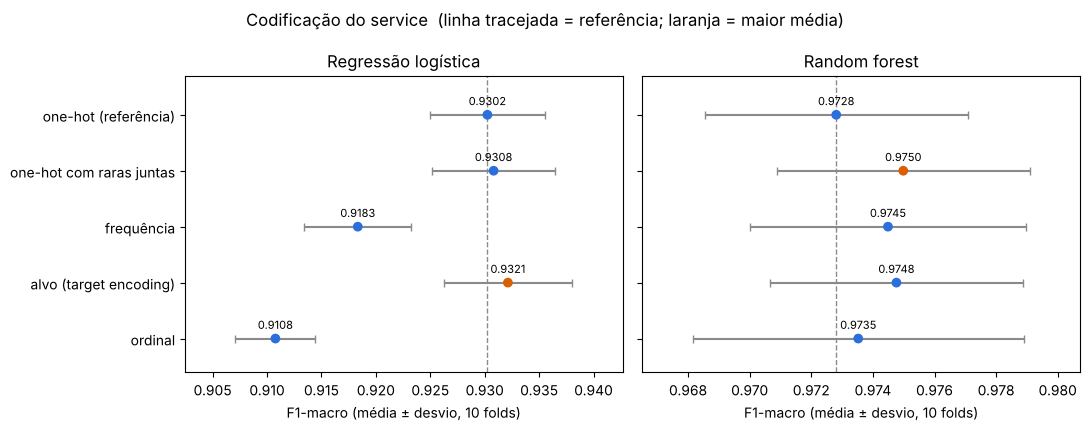

In [20]:
grafico_comparacao(res_cod, "Codificação do service")

In [21]:
COD_NOME = escolher(res_cod, referencia="one-hot (referência)")
ESCOLHA = TEC_COD[COD_NOME]

modelo,dif. Random forest,dif. Regressão logística,não piora nenhum,ganha em ≥8/10 em algum,passa
técnica,,,,,
one-hot (referência),0.0000,0.0000,—,—,—
one-hot com raras juntas,0.0022,0.0006,True,True,True
frequência,0.0017,-0.0119,False,False,False
alvo (target encoding),0.0020,0.0019,True,False,False
ordinal,0.0007,-0.0195,False,False,False


Escolhida: one-hot com raras juntas


**Conclusão do passo 3**

- **One-hot com raras juntas** ganhou da referência na random forest em todos os 10 folds (+0,0022, ganhou em 10 de 10 folds) e empatou na regressão logística (+0,0006, ganhou em 5 de 10 folds). Juntar os serviços raros tira 47 colunas quase sempre zeradas, que apareciam em tão poucas linhas que davam pouco para o modelo aprender.
- A codificação pelo **alvo** chegou perto: melhorou os dois modelos (+0,0019, ganhou em 7 de 10 folds na regressão logística e +0,0020, ganhou em 6 de 10 folds na random forest) e teve a maior média na regressão logística. Mas não ganhou em 8 dos 10 folds em nenhum dos dois, então pela regra não dá para separar essa melhora de sorte na divisão dos folds. Ela também é a única que usa o rótulo para codificar, o que pede mais cuidado.
- **Frequência** ajudou um pouco a random forest (+0,0017, ganhou em 6 de 10 folds), mas derrubou a regressão logística (−0,0119, ganhou em 0 de 10 folds), que perdeu nos 10 folds. É o efeito das colisões: serviços diferentes viram o mesmo número, e um modelo linear ainda lê esse número como "mais é maior".
- **Ordinal** foi a pior na regressão logística (−0,0195, ganhou em 0 de 10 folds), como esperado: a ordem alfabética não quer dizer nada. Na random forest quase não mudou (+0,0007, ganhou em 6 de 10 folds), porque as árvores conseguem separar os números em vários cortes.
- **Escolha: one-hot com raras juntas.** Foi a única que passou na regra. Ela não depende do rótulo (sem risco de vazamento), trata os serviços novos do teste e entrega 69 colunas em vez de 116, o que também deixa mais leve o PCA da Pessoa 3 e o SMOTE da Pessoa 4.

### 4. Conferindo a escolha no teste

Ajusto o pré-processamento escolhido no treino inteiro e aplico no teste, que é o que a Pessoa 4 vai fazer no final. Confiro que não sobra nenhum `NaN`, que o teste continua com todas as linhas, que treino e teste saem com as mesmas colunas e que os dois serviços novos do teste não quebram nada.

In [22]:
# a configuração escolhida, do jeito que a Pessoa 4 vai usar
pre_final = montar_preprocessador(**ESCOLHA)
pre_final.fit(X, y)
Xt_treino = pre_final.transform(X)
Xt_teste = pre_final.transform(X_teste)
nomes = pre_final.get_feature_names_out()

conferencias = {
    "nenhum NaN depois do pré-processamento (treino)": not np.isnan(Xt_treino).any(),
    "nenhum NaN depois do pré-processamento (teste)": not np.isnan(Xt_teste).any(),
    "teste continua com 24.333 linhas": Xt_teste.shape[0] == 24333,
    "treino e teste com as mesmas colunas": Xt_treino.shape[1] == Xt_teste.shape[1],
    "serviços novos do teste caem na coluna dos raros": bool(
        (Xt_teste[X_teste["service"].isin(so_teste).to_numpy(), list(nomes).index("service_infrequent_sklearn")] == 1).all()),
}
for nome, ok in conferencias.items():
    print("OK  " if ok else "ERRO", nome)
assert all(conferencias.values())
print(f"\nEscolha: {ESCOLHA}")
print(f"Colunas na saída: {Xt_treino.shape[1]} (eram {X.shape[1]} atributos)")
print("Algumas colunas:", list(nomes[:3]), "...", list(nomes[-4:]))

OK   nenhum NaN depois do pré-processamento (treino)
OK   nenhum NaN depois do pré-processamento (teste)
OK   teste continua com 24.333 linhas
OK   treino e teste com as mesmas colunas
OK   serviços novos do teste caem na coluna dos raros

Escolha: {'num': 'mediana', 'cat': 'moda', 'codificacao': 'onehot_raras'}
Colunas na saída: 69 (eram 40 atributos)
Algumas colunas: ['duration', 'src_bytes', 'dst_bytes'] ... ['service_telnet', 'service_time', 'service_urp_i', 'service_infrequent_sklearn']


**Conclusão do passo 4**

- O pré-processamento roda no teste sem erro e sem deixar `NaN`. As 24.333 linhas continuam lá, com as mesmas 69 colunas do treino.
- `pm_dump` e `printer`, que não existem no treino, caem na coluna dos serviços raros (`service_infrequent_sklearn`), em vez de virarem uma linha toda zerada ou darem erro.

### 5. Resumo

Todas as técnicas testadas, com a média do F1-macro nos 10 folds. Os números saem das variáveis do notebook, não foram digitados.

In [23]:
fmt4 = lambda v: f"{v:.4f}"
def linha(res, tec):
    r = res[res["técnica"] == tec].set_index("modelo")
    return [fmt4(r.loc["Regressão logística", "F1-macro"]), fmt4(r.loc["Random forest", "F1-macro"])]

tab = pd.DataFrame(
    [["Imputação", t] + linha(res_imp, t) for t in TEC_IMP] +
    [["Codificação do service", t] + linha(res_cod, t) for t in TEC_COD],
    columns=["etapa", "técnica", "F1-macro (reg. logística)", "F1-macro (random forest)"])
tab["escolhida"] = ["sim" if t in (IMP_NOME, COD_NOME) else "" for t in tab["técnica"]]
display(tab.style.hide(axis="index"))

etapa,técnica,F1-macro (reg. logística),F1-macro (random forest),escolhida
Imputação,mediana (referência),0.9302,0.9728,sim
Imputação,média,0.9304,0.9703,
Imputação,mediana + indicador serror,0.9296,0.9711,
Imputação,mediana + indicadores (todas),0.9300,0.9691,
Imputação,iterativa (multivariada),0.9322,0.9703,
Imputação,mediana + cat. 'ausente',0.9332,0.9715,
Codificação do service,one-hot (referência),0.9302,0.9728,
Codificação do service,one-hot com raras juntas,0.9308,0.9750,sim
Codificação do service,frequência,0.9183,0.9745,
Codificação do service,alvo (target encoding),0.9321,0.9748,


**Para quem for usar (Pessoa 4):**

```python
from ausentes_codificacao import montar_preprocessador

pre = montar_preprocessador(num="mediana", cat="moda", codificacao="onehot_raras")
pipe = Pipeline([("pre", pre), ("modelo", ...)])   # o pré-processamento vem antes de tudo
```

- O `montar_preprocessador()` já inclui um `StandardScaler` nos números. Se a Pessoa 3 escolher outro tratamento (`log1p`, `RobustScaler`), é só trocar essa parte no arquivo.
- Ele tem que ser o **primeiro passo** do pipeline, antes do SMOTE: o SMOTE trabalha com distâncias, então precisa receber tudo já sem `NaN` e em números.
- `X` não pode ter `class` nem `id`. Com `score_ids_legado`, ela entra automaticamente como mais uma coluna numérica.
- Quando o `avaliar()` oficial da Pessoa 1 sair, vale rodar esta seção de novo com ele. Se as escolhas mudarem, a função `escolher()` mostra isso na hora; só o texto das conclusões teria que ser atualizado.

## Pessoa 3 — Transformação e redução

**Entrega:** comparação das técnicas e a justificativa.

- Transformação numérica: `log1p` nos bytes e na duração; StandardScaler × RobustScaler
- Redução de dimensionalidade com PCA (ou seleção de instâncias)

### Transformação e redução

Nesta parte da Etapa 2 eu cuido da escala dos atributos numéricos. Parti da base limpa da Pessoa 1 (`treino_limpo.csv`) e da imputação e codificação escolhidas pela Pessoa 2, e comparei:

1. **transformação** com `log1p` nos atributos muito assimétricos (bytes e duração, como pede o enunciado, e uma variante com todas as contagens);
2. **escala** com `StandardScaler` × `RobustScaler` (e sem escala, como referência);
3. **redução de dimensionalidade** com PCA.

Tudo fica dentro de um `Pipeline`, então o `log1p`, os escaladores e o PCA só são ajustados no treino de cada fold. As peças ficam no arquivo `transformacao.py` (o mesmo conteúdo está separado em `etapa2_transformacao.ipynb`). A seção inteira leva uns 40 minutos para rodar, por causa dos 3 modelos em 10 folds.

### 0. Leitura dos dados e avaliação

In [1]:
from pathlib import Path
from time import perf_counter
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

import transformacao as T   # as peças desta parte ficam em transformacao.py

warnings.filterwarnings("ignore", category=UserWarning)   # aviso de categoria desconhecida no one-hot
pd.set_option("display.max_columns", 60)
AZUL, LARANJA, CINZA = "#2a6fdb", "#d95f02", "#8a8a8a"

PASTA = Path("BANCO_DE_DADOS")
treino_limpo = pd.read_csv(PASTA / "treino_limpo.csv")
X, y = T.separar(treino_limpo)    # tira class e score_ids_legado
NUM = T.colunas_numericas(X)

print("X:", X.shape, f"| anomalias: {y.mean() * 100:.2f}%")
print(f"{len(NUM)} numéricas e {len(T.CATEGORICAS)} categóricas")

X: (55074, 40) | anomalias: 3.30%
37 numéricas e 3 categóricas


- **O que vem da Pessoa 2:** mediana nos números, moda nos textos e `service` em one-hot com os serviços raros juntos. `T.montar_preprocessador` usa essas mesmas peças de `ausentes_codificacao.py`; o que muda aqui é só o tratamento dos números.
- **Validação:** a mesma da Pessoa 2, 5 folds estratificados repetidos 2 vezes, com os mesmos folds para todas as técnicas. Por isso, além da média, conto em quantos dos 10 folds cada técnica ganhou da referência. A `avaliar()` da Pessoa 1 ainda não saiu, então uso uma provisória. Ela se chama `avaliar_p3` para não tapar a oficial no notebook do grupo.
- **Modelos:** regressão logística e random forest, os mesmos da Pessoa 2, mais o **KNN**, porque ele trabalha com distâncias e é o mais sensível à escala. O SMOTE da Pessoa 4 também usa distâncias.
- **`score_ids_legado` ficou de fora**, como na Pessoa 2, até o grupo decidir se ela é vazamento.

**Regra de escolha:** a mesma da Pessoa 2, adaptada para três modelos. A técnica não pode ter média menor que a referência em nenhum modelo e precisa ganhar em pelo menos 8 dos 10 folds em pelo menos um. Se nenhuma passar, fico com a referência.

In [2]:
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42)   # os mesmos folds da Pessoa 2

MODELOS_P3 = {
    "Regressão logística": LogisticRegression(max_iter=2000),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Random forest": RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
}


# provisória, até a avaliar() da Pessoa 1 ficar pronta
def avaliar_p3(pipeline, X=X, y=y):
    return cross_validate(pipeline, X, y, cv=CV, scoring="f1_macro", n_jobs=-1)


def comparar_p3(tecnicas, referencia):
    """tecnicas = {nome: pré-processamento}. Roda cada uma em cada modelo e compara
    com a referência fold a fold (os folds são os mesmos para todas)."""
    linhas, folds = [], {}
    for nome_m, modelo in MODELOS_P3.items():
        for nome, pre in tecnicas.items():
            r = avaliar_p3(Pipeline([("pre", pre), ("modelo", modelo)]))
            folds[nome_m, nome] = r["test_score"]
            linhas.append({"modelo": nome_m, "técnica": nome, "f1_macro": r["test_score"].mean(),
                           "desvio": r["test_score"].std(), "treino_s": r["fit_time"].mean()})
    res = pd.DataFrame(linhas)
    dif = [folds[m, t] - folds[m, referencia] for m, t in zip(res["modelo"], res["técnica"])]
    res["dif"] = [d.mean() for d in dif]
    res["ganhou"] = [int((d > 0).sum()) for d in dif]
    return res


def regra_p3(res, referencia, min_folds=8):
    """Mostra a diferença para a referência e quem passa na regra de escolha."""
    tab = res.assign(cel=res["dif"].map("{:+.4f}".format) + " (" + res["ganhou"].astype(str) + "/10)") \
             .pivot(index="técnica", columns="modelo", values="cel").loc[res["técnica"].unique(), list(MODELOS_P3)]
    tab["passa"] = (res[res["dif"] >= 0].groupby("técnica").size().reindex(tab.index, fill_value=0) == len(MODELOS_P3)) \
                   & (res.groupby("técnica")["ganhou"].max().reindex(tab.index) >= min_folds)
    tab = tab.astype({"passa": object})
    tab.loc[referencia, :] = "referência"
    display(tab)
    return [t for t in tab.index if tab.loc[t, "passa"] is True or tab.loc[t, "passa"] == True]

### 1. Por que `log1p`?

Antes de transformar, olho a assimetria (*skewness*) das numéricas. Uma distribuição simétrica tem assimetria perto de 0; acima de 1 já é bem assimétrica. O `log1p(x) = log(1 + x)` comprime os valores grandes e funciona com zero, que é o valor mais comum nessas colunas.

In [3]:
assim = X[NUM].skew()
resumo = pd.DataFrame({
    "assimetria": assim,
    "% zeros": (X[NUM] == 0).mean() * 100,
    "mediana": X[NUM].median(),
    "máximo": X[NUM].max(),
}).sort_values("assimetria", ascending=False)
resumo["log1p na variante contagens"] = resumo.index.isin(T.COLS_LOG_CONTAGENS)
display(resumo.round(2).head(20))
print("colunas 0/1:", [c for c in NUM if set(X[c].dropna().unique()) <= {0, 1}])

,assimetria,% zeros,mediana,máximo,log1p na variante contagens
is_host_login,234.68,100.00,0.0,1.0,False
dst_bytes,215.03,17.28,386.0,209228000.0,True
duration,182.59,87.48,0.0,39603000.0,True
num_root,177.83,99.20,0.0,7468.0,True
urgent,149.46,99.99,0.0,3.0,True
src_bytes,101.58,4.30,227.0,21945520.0,True
land,88.69,99.99,0.0,1.0,False
num_file_creations,65.44,94.39,0.0,100.0,True
num_shells,49.69,99.95,0.0,2.0,True
num_compromised,49.39,93.23,0.0,10300.0,True


colunas 0/1: ['land', 'logged_in', 'root_shell', 'su_attempted', 'is_host_login', 'is_guest_login']


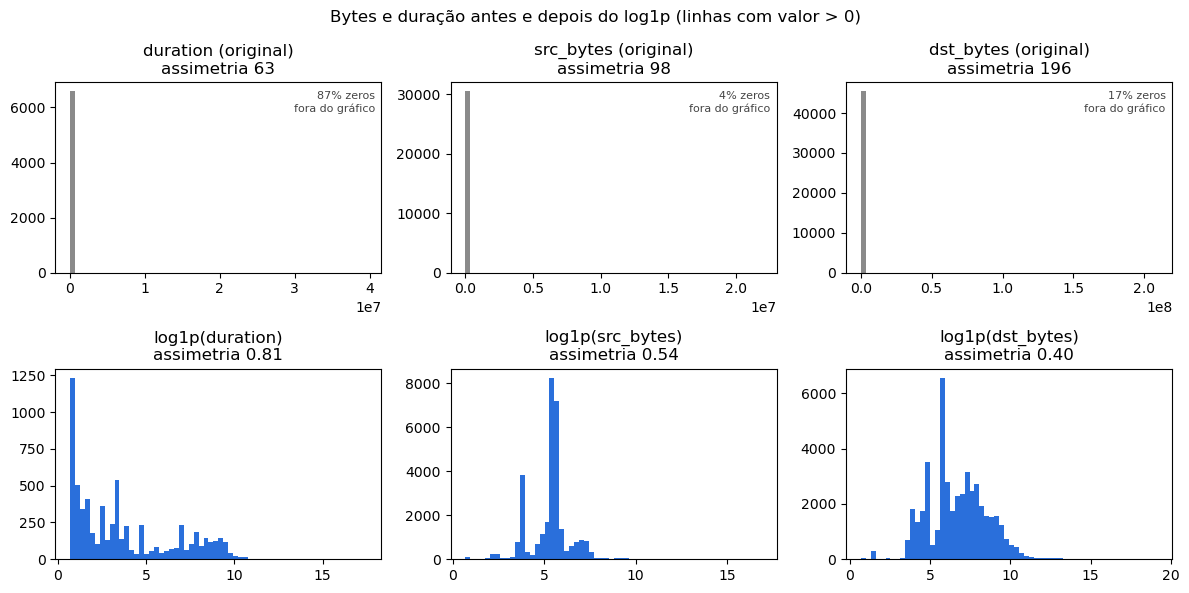

In [4]:
# gráfico 1: bytes e duração antes e depois do log1p (só valores > 0, senão o zero domina)
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for j, c in enumerate(T.COLS_LOG_BYTES):
    v = X[c].dropna()
    v = v[v > 0]
    axes[0, j].hist(v, bins=60, color=CINZA)
    axes[0, j].set_title(f"{c} (original)\nassimetria {v.skew():.0f}")
    axes[1, j].hist(np.log1p(v), bins=60, color=AZUL)
    axes[1, j].set_title(f"log1p({c})\nassimetria {np.log1p(v).skew():.2f}")
    axes[0, j].text(0.98, 0.95, f"{(X[c] == 0).mean():.0%} zeros\nfora do gráfico", transform=axes[0, j].transAxes,
                    ha="right", va="top", fontsize=8, color="#444")
fig.suptitle("Bytes e duração antes e depois do log1p (linhas com valor > 0)")
plt.tight_layout(); plt.show()

**Conclusão da seção 1**

- Os bytes e a duração estão entre as colunas mais assimétricas da base: `dst_bytes` tem assimetria 215, `duration` 183 e `src_bytes` 102. Os máximos chegam a 209 milhões de bytes e 39,6 milhões de segundos, enquanto as medianas são 386, 0 e 227.
- Olhando só os valores acima de zero, o `log1p` derruba a assimetria para menos de 1 nas três (0,81 na duração, 0,54 em `src_bytes` e 0,40 em `dst_bytes`). O gráfico mostra a diferença: antes quase tudo fica espremido numa barra perto do zero; depois aparece a distribuição de verdade.
- `duration` é zero em 87% das linhas. O `log1p` mantém o zero como zero, então essas linhas não mudam.
- Outras contagens também são muito assimétricas (`num_root`, `num_compromised`, `num_file_creations`, `hot`...). Por isso testo também uma variante com `log1p` em **todas as contagens** (16 colunas que não são taxa nem 0/1). As taxas já ficam entre 0 e 1 e as seis colunas 0/1 não têm o que comprimir, então ficam de fora.

### 2. Por que o `RobustScaler` pode não ajudar aqui

O `StandardScaler` subtrai a média e divide pelo desvio padrão. O `RobustScaler` subtrai a mediana e divide pelo intervalo interquartil (IQR = Q3 − Q1), que não é afetado por valores extremos. O problema é quando o IQR é **zero**: aí o sklearn não divide por nada (escala 1), e a coluna fica com os valores originais. Conto quantas colunas estão nessa situação.

In [5]:
q1, q3 = X[NUM].quantile(0.25), X[NUM].quantile(0.75)
iqr = q3 - q1
iqr_zero = iqr[iqr == 0].index.tolist()
print(f"{len(iqr_zero)} de {len(NUM)} numéricas têm IQR = 0")
display(pd.DataFrame({"IQR": iqr[iqr_zero], "máximo": X[iqr_zero].max()})
        .sort_values("máximo", ascending=False).head(10))

25 de 37 numéricas têm IQR = 0


,IQR,máximo
duration,0.0,39603000.0
num_compromised,0.0,10300.0
num_root,0.0,7468.0
hot,0.0,101.0
num_file_creations,0.0,100.0
num_access_files,0.0,9.0
num_failed_logins,0.0,4.0
urgent,0.0,3.0
wrong_fragment,0.0,3.0
num_shells,0.0,2.0


**Conclusão da seção 2**

- 25 das 37 numéricas têm IQR = 0, porque mais de 75% das linhas têm o mesmo valor (quase sempre zero). Nelas o `RobustScaler` só subtrai a mediana e **não muda a escala**.
- Entre elas estão justamente as colunas com valores extremos: `duration` (até 39,6 milhões), `num_compromised` (até 10.300) e `num_root` (até 7.468). Sem `log1p`, esses valores entram no modelo praticamente do jeito que vieram, e a expectativa é que o `RobustScaler` vá mal nesse caso. A seção 3 confirma.

### 3. Comparação: `log1p` × escala

Cruzo três opções de `log1p` (nenhum, só bytes e duração, todas as contagens) com três de escala (nenhuma, `StandardScaler`, `RobustScaler`), nos três modelos. São 27 combinações, cada uma com 10 folds. A **referência** é o que a Pessoa 2 usou até aqui: sem `log1p` e com `StandardScaler`. Ela tem que dar os mesmos 0,9308 e 0,9750 da tabela da Pessoa 2, o que serve de conferência.

In [6]:
OPCOES_LOG = {
    "sem log1p": [],
    "log1p bytes e duração": T.COLS_LOG_BYTES,
    "log1p todas as contagens": T.COLS_LOG_CONTAGENS,
}
ESCALAS = {"sem escala": "nenhum", "StandardScaler": "standard", "RobustScaler": "robust"}
REF_ESCALA = "sem log1p | StandardScaler"

comp = comparar_p3({f"{nome_log} | {nome_esc}": T.montar_preprocessador(cols, esc)
                    for nome_log, cols in OPCOES_LOG.items() for nome_esc, esc in ESCALAS.items()}, REF_ESCALA)
comp[["log1p", "escala"]] = comp["técnica"].str.split(" | ", regex=False, expand=True)

# conferência: a referência é o pipeline da Pessoa 2
r = comp[comp["técnica"] == REF_ESCALA].set_index("modelo")["f1_macro"]
print(f"referência: logística {r['Regressão logística']:.4f} (Pessoa 2: 0.9308) | random forest {r['Random forest']:.4f} (Pessoa 2: 0.9750)")

# tabela: F1-macro médio ± desvio entre os folds
comp["F1-macro"] = comp["f1_macro"].map("{:.4f}".format) + " ± " + comp["desvio"].map("{:.4f}".format)
tabela = comp.pivot(index=["modelo", "log1p"], columns="escala", values="F1-macro")
display(tabela.loc[[(m, l) for m in MODELOS_P3 for l in OPCOES_LOG], list(ESCALAS)])

referência: logística 0.9308 (Pessoa 2: 0.9308) | random forest 0.9750 (Pessoa 2: 0.9750)


escala                                             sem escala  \
modelo              log1p                                       
Regressão logística sem log1p                 0.8942 ± 0.0122   
                    log1p bytes e duração     0.9324 ± 0.0049   
                    log1p todas as contagens  0.9387 ± 0.0053   
KNN (k=5)           sem log1p                 0.9012 ± 0.0044   
                    log1p bytes e duração     0.8812 ± 0.0083   
                    log1p todas as contagens  0.9519 ± 0.0076   
Random forest       sem log1p                 0.9750 ± 0.0040   
                    log1p bytes e duração     0.9750 ± 0.0041   
                    log1p todas as contagens  0.9751 ± 0.0043   

escala                                         StandardScaler     RobustScaler  
modelo              log1p                                                       
Regressão logística sem log1p                 0.9308 ± 0.0057  0.8292 ± 0.0570  
                    log1p bytes e duração     0.9342 ± 0.0055  0.9325 ± 0.0043  
                    log1p todas as contagens  0.9386 ± 0.0054  0.9381 ± 0.0050  
KNN (k=5)           sem log1p                 0.9508 ± 0.0061  0.9151 ± 0.0071  
                    log1p bytes e duração     0.9533 ± 0.0062  0.9232 ± 0.0074  
                    log1p todas as contagens  0.9588 ± 0.0061  0.9272 ± 0.0062  
Random forest       sem log1p                 0.9750 ± 0.0041  0.9748 ± 0.0040  
                    log1p bytes e duração     0.9749 ± 0.0043  0.9748 ± 0.0041  
                    log1p todas as contagens  0.9751 ± 0.0043  0.9751 ± 0.0043

In [7]:
# diferença para a referência e folds ganhos (de 10), em cada modelo
passam = regra_p3(comp, REF_ESCALA)
print("Passam na regra:", passam)

# tempo médio de treino por fold (s) na regressão logística: sem escala o otimizador demora a convergir
display(comp[comp["modelo"] == "Regressão logística"]
        .pivot(index="log1p", columns="escala", values="treino_s").loc[list(OPCOES_LOG), list(ESCALAS)].round(1))

modelo,Regressão logística,KNN (k=5),Random forest,passa
técnica,,,,
sem log1p | sem escala,-0.0366 (0/10),-0.0496 (0/10),+0.0000 (2/10),False
sem log1p | StandardScaler,referência,referência,referência,referência
sem log1p | RobustScaler,-0.1016 (0/10),-0.0357 (0/10),-0.0002 (1/10),False
log1p bytes e duração | sem escala,+0.0016 (7/10),-0.0696 (0/10),+0.0000 (3/10),False
log1p bytes e duração | StandardScaler,+0.0033 (9/10),+0.0025 (7/10),-0.0001 (1/10),False
log1p bytes e duração | RobustScaler,+0.0017 (7/10),-0.0276 (0/10),-0.0002 (2/10),False
log1p todas as contagens | sem escala,+0.0078 (10/10),+0.0010 (7/10),+0.0001 (4/10),True
log1p todas as contagens | StandardScaler,+0.0078 (10/10),+0.0079 (10/10),+0.0002 (4/10),True
log1p todas as contagens | RobustScaler,+0.0073 (10/10),-0.0236 (0/10),+0.0001 (4/10),False


Passam na regra: ['log1p todas as contagens | sem escala', 'log1p todas as contagens | StandardScaler']


escala,sem escala,StandardScaler,RobustScaler
log1p,,,
sem log1p,111.2,6.4,119.0
log1p bytes e duração,94.7,5.9,38.2
log1p todas as contagens,6.0,6.5,29.8


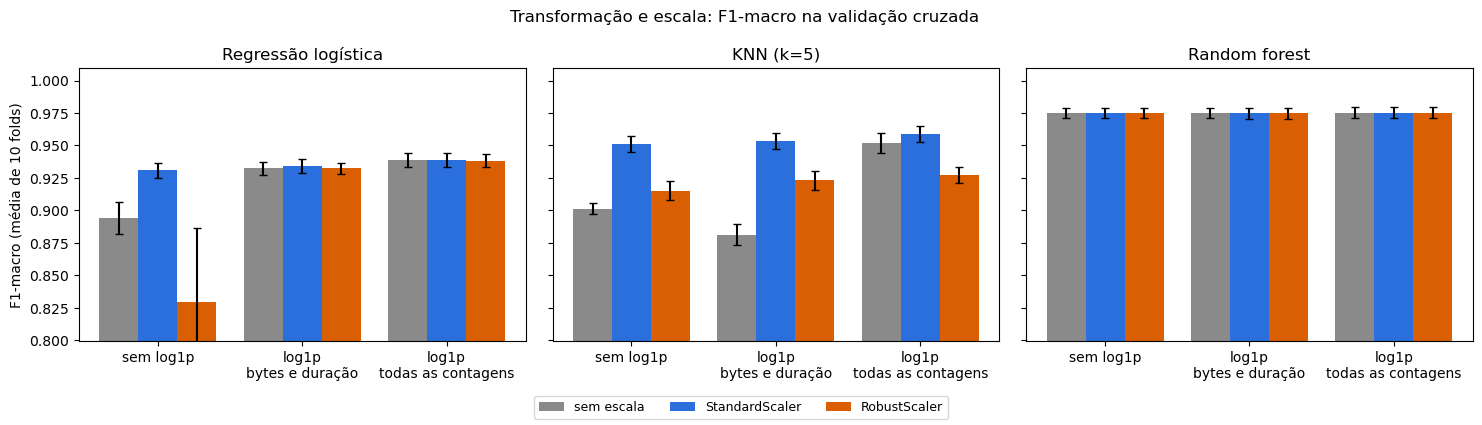

In [8]:
# gráfico 2: F1-macro de cada combinação, com o desvio entre os folds
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
cores = {"sem escala": CINZA, "StandardScaler": AZUL, "RobustScaler": LARANJA}
x = np.arange(len(OPCOES_LOG))
for ax, nome_m in zip(axes, MODELOS_P3):
    sub = comp[comp["modelo"] == nome_m]
    for k, esc in enumerate(ESCALAS):
        s = sub[sub["escala"] == esc].set_index("log1p").loc[list(OPCOES_LOG)]
        ax.bar(x + (k - 1) * 0.27, s["f1_macro"], 0.27, yerr=s["desvio"], capsize=3, color=cores[esc], label=esc)
    ax.set_xticks(x)
    ax.set_xticklabels([n.replace("log1p ", "log1p\n") for n in OPCOES_LOG])
    ax.set_title(nome_m)
axes[0].set_ylim(comp["f1_macro"].min() - 0.03, 1.01)
axes[0].set_ylabel("F1-macro (média de 10 folds)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=9)
fig.suptitle("Transformação e escala: F1-macro na validação cruzada")
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

**Conclusão da seção 3**

- **Conferência:** a referência deu 0,9308 na logística e 0,9750 na random forest, os mesmos números da Pessoa 2. Ou seja, o pré-processamento daqui só difere do dela no que estou testando.
- **`log1p` em todas as contagens com `StandardScaler` ganhou da referência em todos os 10 folds nos dois modelos sensíveis à escala:** +0,0078 na logística (0,9386) e +0,0079 no KNN (0,9588).
- **Só bytes e duração, como pede o enunciado, ajuda menos:** +0,0033 na logística (9 de 10 folds) e +0,0025 no KNN (7 de 10). Na random forest fica em −0,0001, então não passa na regra por muito pouco.
- **Na random forest nada disso faz diferença:** as 9 combinações ficam entre 0,9748 e 0,9751. As árvores só olham a ordem dos valores, e o `log1p` e os escaladores não mudam essa ordem.
- **O `RobustScaler` é o que mais sofre sem `log1p`:** 0,8292 na logística, com o maior desvio da tabela (0,057) e −0,1016 em relação à referência. É o efeito da seção 2: com IQR = 0, os valores extremos continuam lá. Com `log1p` em todas as contagens ele se recupera na logística (0,9381), mas não no KNN (0,9272, −0,0236 e 0 de 10 folds), porque continua deixando as 25 colunas sem escala.
- **No KNN, escalar é indispensável.** O KNN mede distâncias, e a coluna com números maiores manda. Sem escala ele fica em 0,9012, e com `log1p` só nos bytes cai ainda mais (0,8812), provavelmente porque as outras contagens, que vão até 511, passam a dominar a distância.
- **A escala também pesa no tempo da logística:** sem `log1p`, sem escala ou com `RobustScaler`, o treino de um fold leva de dezenas de segundos a mais de um minuto, contra uns 2 s com `StandardScaler`. Os tempos variam a cada execução, mas a diferença é sempre grande.

**Escolha: `log1p` em todas as contagens + `StandardScaler`** (`T.montar_preprocessador(T.COLS_LOG_CONTAGENS, "standard")`). Duas combinações passaram na regra: esta e a mesma sem escala. Fico com o `StandardScaler` porque ele é bem melhor no KNN (+0,0079 contra +0,0010) e não perde em nenhum dos outros dois modelos. É essa configuração que uso como base para o PCA na próxima seção.

### 4. Redução de dimensionalidade com PCA

Depois do pré-processamento escolhido, cada linha vira um vetor com as 37 numéricas mais as colunas do one-hot. O PCA troca essas colunas por um número menor de combinações lineares delas (os componentes), escolhidas para guardar o máximo possível da **variância**. É não supervisionado: não olha a classe. Como depende da escala, ele entra depois do `StandardScaler`.

Primeiro vejo quantos componentes são precisos para guardar 80%, 90%, 95% e 99% da variância. Esse ajuste no treino inteiro serve só para o gráfico; na avaliação o PCA é ajustado dentro de cada fold, como o resto.

colunas depois do pré-processamento: 69
componentes para guardar a variância: {'80%': 18, '90%': 24, '95%': 28, '99%': 37}


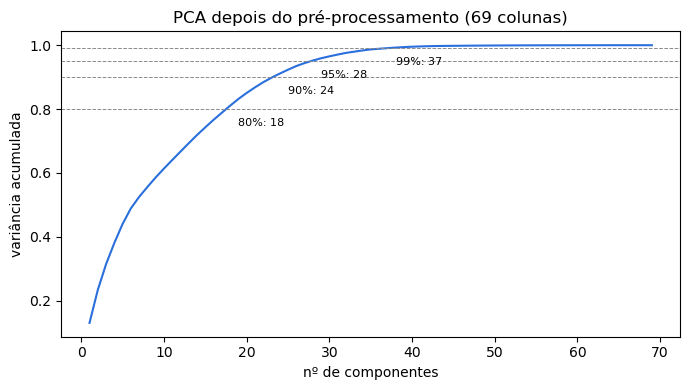

In [9]:
PRE_ESCOLHIDO = dict(cols_log=T.COLS_LOG_CONTAGENS, escalador="standard")

Z = T.montar_preprocessador(**PRE_ESCOLHIDO).fit_transform(X)
var_acum = np.cumsum(PCA().fit(Z).explained_variance_ratio_)
n_para = {f"{q:.0%}": int(np.searchsorted(var_acum, q) + 1) for q in [0.80, 0.90, 0.95, 0.99]}
print("colunas depois do pré-processamento:", Z.shape[1])
print("componentes para guardar a variância:", n_para)

# gráfico 3: variância acumulada
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(var_acum) + 1), var_acum, color=AZUL)
for q, k in n_para.items():
    ax.axhline(float(q[:-1]) / 100, color=CINZA, lw=0.7, ls="--")
    ax.annotate(f"{q}: {k}", (k, float(q[:-1]) / 100), xytext=(6, -12), textcoords="offset points", fontsize=8)
ax.set_xlabel("nº de componentes")
ax.set_ylabel("variância acumulada")
ax.set_title(f"PCA depois do pré-processamento ({Z.shape[1]} colunas)")
plt.tight_layout(); plt.show()

Agora comparo, nos três modelos, o pipeline sem PCA (a referência daqui) com o PCA guardando 90%, 95% e 99% da variância, e com números fixos de componentes (5, 10 e 20). O possível ganho de tempo, que é onde o PCA costuma ajudar o KNN, fica para a seção 5.

In [10]:
OPCOES_PCA = {"PCA 90%": 0.90, "PCA 95%": 0.95, "PCA 99%": 0.99, "PCA 5": 5, "PCA 10": 10, "PCA 20": 20}

def n_colunas(pre):
    # quantas colunas chegam no modelo (ajuste no treino inteiro, só para contar)
    return pre.fit_transform(X).shape[1]

tec_pca = {"sem PCA": T.montar_preprocessador(**PRE_ESCOLHIDO)}
for nome, k in OPCOES_PCA.items():
    tec_pca[nome] = T.com_pca(T.montar_preprocessador(**PRE_ESCOLHIDO), k)

pca_tudo = comparar_p3(tec_pca, "sem PCA")
pca_tudo["colunas"] = pca_tudo["técnica"].map({t: n_colunas(p) for t, p in tec_pca.items()})
display(pca_tudo[["modelo", "técnica", "colunas", "f1_macro", "desvio", "dif", "ganhou"]].round(4))
print("Passam na regra:", regra_p3(pca_tudo, "sem PCA"))

,modelo,técnica,colunas,f1_macro,desvio,dif,ganhou
0,Regressão logística,sem PCA,69,0.9386,0.0054,0.0000,0
1,Regressão logística,PCA 90%,24,0.9027,0.0056,-0.0359,0
2,Regressão logística,PCA 95%,28,0.9054,0.0080,-0.0332,0
3,Regressão logística,PCA 99%,37,0.9041,0.0057,-0.0345,0
4,Regressão logística,PCA 5,5,0.9016,0.0045,-0.0370,0
5,Regressão logística,PCA 10,10,0.8956,0.0058,-0.0430,0
6,Regressão logística,PCA 20,20,0.8916,0.0064,-0.0470,0
7,KNN (k=5),sem PCA,69,0.9588,0.0061,0.0000,0
8,KNN (k=5),PCA 90%,24,0.9509,0.0077,-0.0078,0
9,KNN (k=5),PCA 95%,28,0.9525,0.0079,-0.0063,0


modelo,Regressão logística,KNN (k=5),Random forest,passa
técnica,,,,
sem PCA,referência,referência,referência,referência
PCA 90%,-0.0359 (0/10),-0.0078 (0/10),-0.0252 (0/10),False
PCA 95%,-0.0332 (0/10),-0.0063 (0/10),-0.0244 (0/10),False
PCA 99%,-0.0345 (0/10),-0.0046 (0/10),-0.0228 (0/10),False
PCA 5,-0.0370 (0/10),-0.0310 (0/10),-0.0463 (0/10),False
PCA 10,-0.0430 (0/10),-0.0164 (0/10),-0.0272 (0/10),False
PCA 20,-0.0470 (0/10),-0.0098 (0/10),-0.0233 (0/10),False


Passam na regra: []


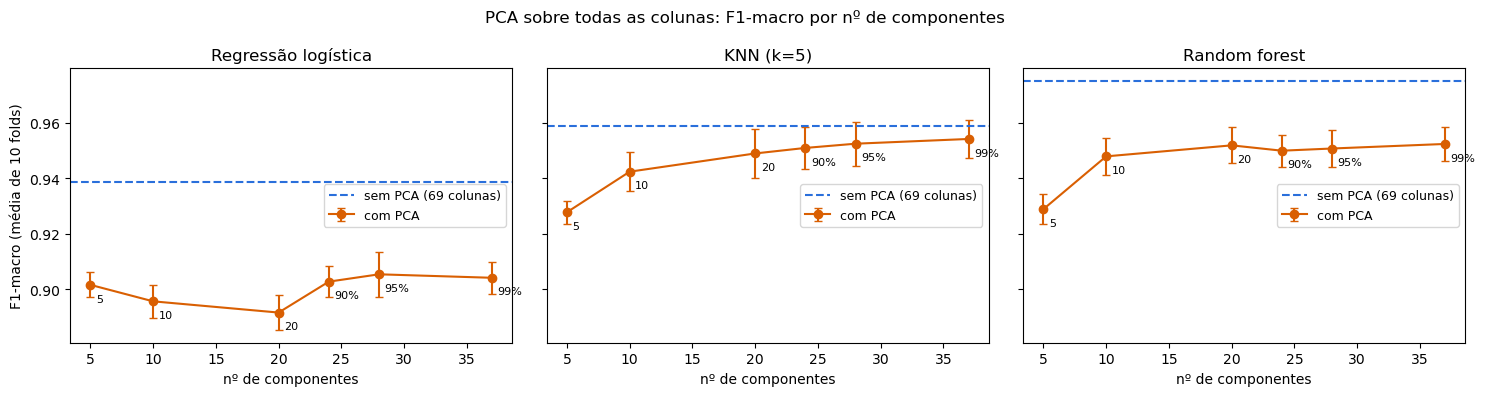

In [11]:
# gráfico 4: F1-macro x nº de colunas que chegam no modelo
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, nome_m in zip(axes, MODELOS_P3):
    s = pca_tudo[(pca_tudo["modelo"] == nome_m) & (pca_tudo["técnica"] != "sem PCA")].sort_values("colunas")
    base = pca_tudo[(pca_tudo["modelo"] == nome_m) & (pca_tudo["técnica"] == "sem PCA")].iloc[0]
    ax.errorbar(s["colunas"], s["f1_macro"], yerr=s["desvio"], marker="o", capsize=3, color=LARANJA, label="com PCA")
    ax.axhline(base["f1_macro"], color=AZUL, ls="--", label=f"sem PCA ({base['colunas']} colunas)")
    for _, l in s.iterrows():
        ax.annotate(l["técnica"].replace("PCA ", ""), (l["colunas"], l["f1_macro"]), xytext=(4, -12), textcoords="offset points", fontsize=8)
    ax.set_xlabel("nº de componentes")
    ax.set_title(nome_m)
    ax.legend(loc="center right", fontsize=9)
axes[0].set_ylabel("F1-macro (média de 10 folds)")
fig.suptitle("PCA sobre todas as colunas: F1-macro por nº de componentes")
plt.tight_layout(); plt.show()

**Conclusão da seção 4**

- Depois do pré-processamento são 69 colunas (37 numéricas e 32 do one-hot). Com 28 componentes o PCA já guarda 95% da variância, e com 37, 99%: dá para quase cortar as colunas pela metade "perdendo" pouca variância.
- **Mas o F1-macro caiu nos três modelos, em todos os 10 folds, com qualquer número de componentes.** Nenhuma opção passou na regra.
- A maior perda na comparação entre as melhores opções é da regressão logística: de 0,9386 sem PCA para no máximo 0,9054 (95%), −0,0332. Guardar 99% da variância (0,9041) não ajuda em relação a 90% (0,9027).
- A **random forest**, o modelo mais forte, também perde bastante: de 0,9751 para no máximo 0,9524 (99%), −0,0228.
- No KNN a perda é menor (0,9588 sem PCA e 0,9542 com 99%), mas cresce com poucos componentes: 0,9277 com 5.
- Perder 1% da variância e 0,02 a 0,03 de F1 ao mesmo tempo indica que parte da informação útil está em direções de **pouca** variância. A seção 5 investiga isso.

### 5. Por que o PCA perdeu informação

O PCA guarda as direções de maior variância, mas **variância não é o mesmo que poder de separar as classes**. Depois do `StandardScaler`, cada numérica tem variância 1. Já uma coluna do one-hot com proporção *p* de uns tem variância *p*(1 − *p*), que é muito pequena para as categorias raras. Comparo quanto da variância total vem de cada grupo e se as categorias de `service` dizem algo sobre a classe.

In [12]:
n_num = len(NUM)
var_col = Z.var(axis=0)
print(f"variância total: {var_col.sum():.1f}")
print(f"  numéricas ({n_num} colunas): {var_col[:n_num].sum():.1f} ({var_col[:n_num].sum() / var_col.sum():.1%})")
print(f"  one-hot ({Z.shape[1] - n_num} colunas): {var_col[n_num:].sum():.1f} ({var_col[n_num:].sum() / var_col.sum():.1%})")

# serviços com mais anomalias, entre os que têm coluna própria no one-hot (50 linhas ou mais)
por_servico = treino_limpo.groupby("service")["class"].agg(linhas="size", pct_anomalias=lambda s: (s == "anomaly").mean() * 100)
por_servico["variância no one-hot"] = (por_servico["linhas"] / len(treino_limpo)) * (1 - por_servico["linhas"] / len(treino_limpo))
display(por_servico[por_servico["linhas"] >= 50].sort_values("pct_anomalias", ascending=False).head(8).round(4))

variância total: 38.1
  numéricas (37 colunas): 37.0 (97.2%)
  one-hot (32 colunas): 1.1 (2.8%)


,linhas,pct_anomalias,variância no one-hot
service,,,
private,1762,34.4495,0.0310
ecr_i,212,32.5472,0.0038
eco_i,402,25.1244,0.0072
time,59,20.3390,0.0011
pop_3,148,12.8378,0.0027
telnet,672,10.7143,0.0121
auth,171,10.5263,0.0031
finger,438,7.3059,0.0079


Se o problema é o PCA misturar as colunas do one-hot com as numéricas, a solução é aplicar o PCA **só nas numéricas** e deixar o one-hot passar direto. É o que faz `T.montar_preprocessador(..., pca_numericas=k)`.

In [13]:
tec_num = {"sem PCA": T.montar_preprocessador(**PRE_ESCOLHIDO)}
for q in [0.90, 0.95, 0.99]:
    tec_num[f"PCA {q:.0%} (só numéricas)"] = T.montar_preprocessador(**PRE_ESCOLHIDO, pca_numericas=q)

pca_num = comparar_p3(tec_num, "sem PCA")
pca_num["colunas"] = pca_num["técnica"].map({t: n_colunas(p) for t, p in tec_num.items()})
display(pca_num[["modelo", "técnica", "colunas", "f1_macro", "desvio", "dif", "ganhou"]].round(4))
print("Passam na regra:", regra_p3(pca_num, "sem PCA"))

,modelo,técnica,colunas,f1_macro,desvio,dif,ganhou
0,Regressão logística,sem PCA,69,0.9386,0.0054,0.0000,0
1,Regressão logística,PCA 90% (só numéricas),55,0.9386,0.0061,-0.0000,6
2,Regressão logística,PCA 95% (só numéricas),59,0.9386,0.0049,-0.0000,5
3,Regressão logística,PCA 99% (só numéricas),65,0.9384,0.0046,-0.0002,5
4,KNN (k=5),sem PCA,69,0.9588,0.0061,0.0000,0
5,KNN (k=5),PCA 90% (só numéricas),55,0.9585,0.0081,-0.0002,4
6,KNN (k=5),PCA 95% (só numéricas),59,0.9610,0.0071,0.0022,9
7,KNN (k=5),PCA 99% (só numéricas),65,0.9598,0.0068,0.0011,6
8,Random forest,sem PCA,69,0.9751,0.0043,0.0000,0
9,Random forest,PCA 90% (só numéricas),55,0.9641,0.0062,-0.0110,0


modelo,Regressão logística,KNN (k=5),Random forest,passa
técnica,,,,
sem PCA,referência,referência,referência,referência
PCA 90% (só numéricas),-0.0000 (6/10),-0.0002 (4/10),-0.0110 (0/10),False
PCA 95% (só numéricas),-0.0000 (5/10),+0.0022 (9/10),-0.0118 (0/10),False
PCA 99% (só numéricas),-0.0002 (5/10),+0.0011 (6/10),-0.0125 (0/10),False


Passam na regra: []


Falta ver se o PCA compensa em tempo no KNN. Os tempos da validação cruzada não servem para isso, porque os folds rodam em paralelo e um atrapalha o outro. Então meço à parte: treino em um fold e cronometro só a previsão, sem paralelismo, três vezes, ficando com a menor.

In [14]:
def tempo_previsao(pre):
    i_tr, i_va = next(CV.split(X, y))
    pipe = Pipeline([("pre", pre), ("modelo", KNeighborsClassifier(n_neighbors=5))]).fit(X.iloc[i_tr], y.iloc[i_tr])
    tempos = []
    for _ in range(3):
        t0 = perf_counter()
        pipe.predict(X.iloc[i_va])
        tempos.append(perf_counter() - t0)
    return min(tempos)

medir = {"sem PCA": tec_pca["sem PCA"], "PCA 95%": tec_pca["PCA 95%"],
         "PCA 95% (só numéricas)": tec_num["PCA 95% (só numéricas)"], "PCA 5": tec_pca["PCA 5"]}
display(pd.Series({t: tempo_previsao(p) for t, p in medir.items()}, name="previsão de um fold no KNN (s)").round(2).to_frame())

,previsão de um fold no KNN (s)
sem PCA,0.89
PCA 95%,0.63
PCA 95% (só numéricas),0.85
PCA 5,0.17


**Conclusão da seção 5**

- Depois do `StandardScaler`, as 37 numéricas somam 97,2% da variância total e as 32 colunas do one-hot só 2,8%. Para o PCA, as categorias quase não existem.
- Só que várias categorias de `service` separam bem as classes: `private` tem 34% de anomalias, `ecr_i` 33% e `eco_i` 25%, contra 3,3% na base toda. Mesmo assim, a coluna de `private` tem variância 0,03, e as outras ainda menos. **Variância baixa não quer dizer pouca informação sobre a classe**, e o PCA, por ser não supervisionado, não tem como saber disso.
- Aplicando o PCA **só nas numéricas**, a logística volta ao nível de sem PCA (diferença de no máximo 0,0002) e o KNN até melhora um pouco com 95% (+0,0022, 9 de 10 folds). Isso confirma que boa parte do problema na logística e no KNN era misturar o one-hot.
- **Mas a random forest continua perdendo:** −0,0110 a −0,0125, em todos os 10 folds. Então o one-hot não explica tudo. A explicação provável, que não testei à parte, é que as árvores cortam uma coluna por vez, e o PCA troca colunas com sentido próprio por misturas de todas elas, em que esses cortes ficam mais difíceis. Por isso nenhuma opção passou na regra.
- **O ganho de tempo é pequeno.** Medindo isolado, a previsão de um fold no KNN leva cerca de 0,9 s sem PCA, 0,6 s com PCA 95% em todas as colunas e 0,85 s com PCA 95% só nas numéricas (os tempos variam com a carga da máquina, mas a proporção é essa). Só com 5 componentes ela fica bem mais rápida (cerca de 0,2 s), mas aí o F1 cai para 0,9277.

### 6. Conferindo a escolha no teste

Ajusto o pré-processamento escolhido no treino e aplico no teste, para ver se nada quebra. O `log1p` é a parte que pede cuidado: um valor negativo viraria `NaN` ou infinito, e a limpeza da Pessoa 1 só corrige negativos em `duration`, `src_bytes` e `dst_bytes`.

In [15]:
teste_limpo = pd.read_csv(PASTA / "teste_limpo.csv")
X_teste = teste_limpo[X.columns]

pre_p3 = T.montar_preprocessador(**PRE_ESCOLHIDO).fit(X, y)
Zt_treino, Zt_teste = pre_p3.transform(X), pre_p3.transform(X_teste)

conferencias = {
    "nenhum negativo nas colunas do log1p (treino e teste)": bool((X[T.COLS_LOG_CONTAGENS].min() >= 0).all() and (X_teste[T.COLS_LOG_CONTAGENS].min() >= 0).all()),
    "nenhum NaN ou infinito na saída (treino e teste)": bool(np.isfinite(Zt_treino).all() and np.isfinite(Zt_teste).all()),
    "teste continua com 24.333 linhas": Zt_teste.shape[0] == 24333,
    "treino e teste com as mesmas colunas": Zt_treino.shape[1] == Zt_teste.shape[1],
    "mesmas colunas da escolha da Pessoa 2 (69)": Zt_treino.shape[1] == 69,
}
for nome, ok in conferencias.items():
    print("OK  " if ok else "ERRO", nome)
assert all(conferencias.values())

OK   nenhum negativo nas colunas do log1p (treino e teste)
OK   nenhum NaN ou infinito na saída (treino e teste)
OK   teste continua com 24.333 linhas
OK   treino e teste com as mesmas colunas
OK   mesmas colunas da escolha da Pessoa 2 (69)


### 7. Resumo e escolha

In [16]:
# resultado de cada etapa, para a tabela comparativa geral da Pessoa 4
resumo_p3 = pd.concat([
    comp[comp["técnica"] == "sem log1p | sem escala"].assign(etapa="sem log1p e sem escala"),
    comp[comp["técnica"] == REF_ESCALA].assign(etapa="sem log1p + StandardScaler (Pessoa 2)"),
    comp[comp["técnica"] == "log1p todas as contagens | StandardScaler"].assign(etapa="log1p contagens + StandardScaler"),
    pca_tudo[pca_tudo["técnica"] == "PCA 95%"].assign(etapa="+ PCA 95% (todas as colunas)"),
    pca_num[pca_num["técnica"] == "PCA 95% (só numéricas)"].assign(etapa="+ PCA 95% (só numéricas)"),
])
resumo_p3["F1-macro"] = resumo_p3["f1_macro"].map("{:.4f}".format) + " ± " + resumo_p3["desvio"].map("{:.4f}".format)
display(resumo_p3.pivot(index="etapa", columns="modelo", values="F1-macro").loc[resumo_p3["etapa"].unique(), list(MODELOS_P3)])

modelo,Regressão logística,KNN (k=5),Random forest
etapa,,,
sem log1p e sem escala,0.8942 ± 0.0122,0.9012 ± 0.0044,0.9750 ± 0.0040
sem log1p + StandardScaler (Pessoa 2),0.9308 ± 0.0057,0.9508 ± 0.0061,0.9750 ± 0.0041
log1p contagens + StandardScaler,0.9386 ± 0.0054,0.9588 ± 0.0061,0.9751 ± 0.0043
+ PCA 95% (todas as colunas),0.9054 ± 0.0080,0.9525 ± 0.0079,0.9507 ± 0.0066
+ PCA 95% (só numéricas),0.9386 ± 0.0049,0.9610 ± 0.0071,0.9633 ± 0.0072


**Conclusão**

| Técnica | O que aconteceu | Decisão |
|---|---|---|
| `log1p` | Reduz a assimetria dos bytes e da duração de mais de 100 para menos de 1. Em todas as 16 contagens, ganha +0,0078 na logística e +0,0079 no KNN (10 de 10 folds); a random forest não muda. | **Usar**, em todas as contagens (`T.COLS_LOG_CONTAGENS`). |
| `StandardScaler` × `RobustScaler` | O `RobustScaler` não escala as 25 colunas com IQR = 0, vai muito mal sem `log1p` e continua pior no KNN (0,9272 contra 0,9588). Na random forest os dois empatam. | **`StandardScaler`**. |
| PCA em todas as colunas | Guarda 95% da variância com 28 de 69 colunas, mas perde F1 nos três modelos: −0,0332 na logística, −0,0244 na random forest e −0,0063 no KNN (com 95%). | **Não usar.** |
| PCA só nas numéricas | Mantém a logística e melhora um pouco o KNN, mas tira cerca de 0,012 da random forest e reduz pouco (69 → 59 colunas com 95%). | **Não usar.** |

**Pipeline recomendado:** `T.montar_preprocessador(T.COLS_LOG_CONTAGENS, "standard")`, sem PCA. F1-macro de 0,9386 na regressão logística, 0,9588 no KNN e 0,9751 na random forest, contra 0,9308, 0,9508 e 0,9750 só com o `StandardScaler`.

**Para a Pessoa 4:**
- Essa função já inclui a imputação e a codificação escolhidas pela Pessoa 2 (mediana, moda e one-hot com raras juntas), então ela entra **no lugar** do `montar_preprocessador` de `ausentes_codificacao.py`, como primeiro passo do pipeline. São as mesmas 69 colunas.
- Se o modelo final for a random forest, o `log1p` e o `StandardScaler` não mudam o resultado, mas também não atrapalham. O PCA atrapalha, e isso já foi medido aqui.
- O SMOTE trabalha com distâncias, então a escala deve importar para ele como importa para o KNN. Isso eu não testei; fica para a comparação de balanceamento.
- `score_ids_legado` ficou de fora em todos os testes daqui, e a `avaliar_p3` é provisória até sair a `avaliar()` da Pessoa 1.

## Pessoa 4 — Balanceamento e integração

**Entrega:** comparação do balanceamento, notebook integrado e tabela final.

- SMOTE × RandomUnderSampler (Pipeline do imblearn), mais `class_weight="balanced"` como referência
- Juntar as partes no notebook final
- Montar a tabela comparativa geral

### Balanceamento: como comparei

Só 3,3% das linhas do treino são `anomaly`. Com tão poucos exemplos, o modelo tende a favorecer a classe `normal`, e o F1-macro, que dá o mesmo peso às duas classes, cobra isso. Nesta parte comparo três jeitos de compensar o desbalanceamento e depois junto tudo num pipeline final.

- **`class_weight="balanced"` (referência de balanceamento, como pede o enunciado):** não mexe nos dados. O erro numa anomalia passa a pesar mais no treino do modelo. Só existe na regressão logística e na random forest; o KNN não tem esse parâmetro.
- **`RandomUnderSampler`:** sorteia linhas `normal` e descarta o resto até as duas classes ficarem do mesmo tamanho. O treino fica bem menor.
- **`SMOTE`:** cria anomalias sintéticas, interpolando entre uma anomalia e uma das 5 anomalias mais próximas, até as classes empatarem.
- **"Sem balanceamento"** é o pipeline escolhido pela Pessoa 3. Ele é a base da regra de escolha e serve de conferência: tem que dar os mesmos números dela.

**Tudo dentro do `Pipeline` do `imblearn`.** A reamostragem só acontece no `fit`, ou seja, só no treino de cada fold. A validação continua com a proporção real de 3,3%, que é a que o modelo vai encontrar no teste. Fazer o SMOTE antes da validação cruzada colocaria anomalias sintéticas, feitas a partir das linhas de validação, dentro do treino.

**O que vem das outras partes:** a limpeza da Pessoa 1, a imputação e a codificação da Pessoa 2 e o `log1p` nas contagens com `StandardScaler` da Pessoa 3 (`T.montar_preprocessador(T.COLS_LOG_CONTAGENS, "standard")`). O balanceamento entra **depois** desse pré-processamento, porque o SMOTE mede distâncias e precisa dos dados sem `NaN`, em números e na mesma escala.

**Validação e regra de escolha:** as mesmas das Pessoas 2 e 3. São 5 folds estratificados repetidos 2 vezes (os mesmos folds de todo o grupo), F1-macro e os três modelos da Pessoa 3. Como nas outras partes, a técnica é comparada com o pipeline que já temos, ou seja, **sem balanceamento**: ela não pode ter média menor em nenhum modelo e precisa ganhar em pelo menos 8 dos 10 folds em pelo menos um. Entre as que passam, fico com a de maior F1-macro na random forest. O `class_weight` é a referência **entre as técnicas de balanceamento**, por ser a mais simples, e por isso entra na regra como mais uma candidata. Além do F1-macro, guardo a precisão e o recall da classe `anomaly`, que explicam de onde vem cada diferença.

**Uma limitação do SMOTE aqui:** ele interpola também as colunas do one-hot, então uma anomalia sintética pode ter `service_http = 0,4`. O `SMOTENC` trata as categóricas à parte, mas exigiria mudar o pré-processamento das outras partes. Fico com o SMOTE comum, como pede o enunciado.

`score_ids_legado` continua de fora, como nas outras partes.

In [40]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

import limpeza as L
import transformacao as T

warnings.filterwarnings("ignore", category=UserWarning)   # aviso de categoria desconhecida no one-hot
AZUL, LARANJA, CINZA = "#2a6fdb", "#d95f02", "#8a8a8a"

PASTA = Path("BANCO_DE_DADOS")
X, y = T.separar(pd.read_csv(PASTA / "treino_limpo.csv"))   # tira class e score_ids_legado

PRE_FINAL = dict(cols_log=T.COLS_LOG_CONTAGENS, escalador="standard")   # a escolha da Pessoa 3
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42)    # os mesmos folds de todo o grupo
METRICAS = {"f1_macro": "f1_macro", "precisao": "precision", "recall": "recall"}   # precisão e recall da classe anomaly

MODELOS_P4 = {
    "Regressão logística": LogisticRegression(max_iter=2000),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Random forest": RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
}

# nome: (amostrador, usa class_weight). O amostrador fica entre o pré-processamento e o modelo
BALANCEAMENTOS = {
    "sem balanceamento": (None, False),
    "class_weight balanced": (None, True),
    "RandomUnderSampler": (RandomUnderSampler(random_state=42), False),
    "SMOTE": (SMOTE(random_state=42), False),
}
REF = "sem balanceamento"   # o pipeline da Pessoa 3; base da regra de escolha


def aplica(balanceamento, modelo):
    """False só para class_weight no KNN, que não tem esse parâmetro."""
    return not BALANCEAMENTOS[balanceamento][1] or "class_weight" in modelo.get_params()


def montar_pipeline(balanceamento, modelo):
    """pré-processamento (Pessoas 2 e 3) -> balanceamento -> modelo, num Pipeline do imblearn:
    o amostrador só age no fit, então só no treino de cada fold."""
    amostrador, pesos = BALANCEAMENTOS[balanceamento]
    modelo = clone(modelo)
    if pesos:
        modelo.set_params(class_weight="balanced")
    return ImbPipeline([("pre", T.montar_preprocessador(**PRE_FINAL)),
                        ("balancear", clone(amostrador) if amostrador else "passthrough"),
                        ("modelo", modelo)])


def avaliar_p4(pipeline, X=X, y=y):
    return cross_validate(pipeline, X, y, cv=CV, scoring=METRICAS, n_jobs=-1)


print("X:", X.shape, f"| anomalias: {y.mean() * 100:.2f}% ({y.sum()} de {len(y)})")

X: (55074, 40) | anomalias: 3.30% (1817 de 55074)


### 1. Comparação: `class_weight` × `RandomUnderSampler` × `SMOTE`

São 4 opções nos 3 modelos, menos o `class_weight` no KNN: 11 combinações, cada uma com 10 folds.

In [41]:
linhas, folds_p4 = [], {}
for nome_m, modelo in MODELOS_P4.items():
    for bal in BALANCEAMENTOS:
        if not aplica(bal, modelo):
            continue
        r = avaliar_p4(montar_pipeline(bal, modelo))
        folds_p4[nome_m, bal] = r["test_f1_macro"]
        linhas.append({"modelo": nome_m, "balanceamento": bal,
                       "f1_macro": r["test_f1_macro"].mean(), "desvio": r["test_f1_macro"].std(),
                       "precisao": r["test_precisao"].mean(), "recall": r["test_recall"].mean(),
                       "treino_s": r["fit_time"].mean()})
bal_res = pd.DataFrame(linhas)

# diferença para o pipeline sem balanceamento, fold a fold (os folds são os mesmos)
dif = [folds_p4[m, b] - folds_p4[m, REF] for m, b in zip(bal_res["modelo"], bal_res["balanceamento"])]
bal_res["dif"] = [d.mean() for d in dif]
bal_res["ganhou"] = [int((d > 0).sum()) for d in dif]

# conferência: sem balanceamento é exatamente o pipeline final da Pessoa 3
r = bal_res[bal_res["balanceamento"] == "sem balanceamento"].set_index("modelo")["f1_macro"]
print("sem balanceamento:", " | ".join(f"{m} {v:.4f}" for m, v in r.items()),
      "\n(Pessoa 3: logística 0.9386 | KNN 0.9588 | random forest 0.9751)")

bal_res["F1-macro"] = bal_res["f1_macro"].map("{:.4f}".format) + " ± " + bal_res["desvio"].map("{:.4f}".format)
display(bal_res.pivot(index="balanceamento", columns="modelo", values="F1-macro")
        .reindex(index=list(BALANCEAMENTOS), columns=list(MODELOS_P4)).fillna("não se aplica"))

sem balanceamento: Regressão logística 0.9387 | KNN (k=5) 0.9588 | Random forest 0.9751 
(Pessoa 3: logística 0.9386 | KNN 0.9588 | random forest 0.9751)


modelo,Regressão logística,KNN (k=5),Random forest
balanceamento,,,
sem balanceamento,0.9387 ± 0.0053,0.9588 ± 0.0061,0.9751 ± 0.0043
class_weight balanced,0.7914 ± 0.0070,não se aplica,0.9793 ± 0.0034
RandomUnderSampler,0.7810 ± 0.0107,0.8488 ± 0.0121,0.8973 ± 0.0132
SMOTE,0.7949 ± 0.0069,0.9388 ± 0.0041,0.9773 ± 0.0035


In [42]:
# regra de escolha: diferença para o sem balanceamento e folds ganhos (de 10)
regra = bal_res.assign(cel=bal_res["dif"].map("{:+.4f}".format) + " (" + bal_res["ganhou"].astype(str) + "/10)")
regra = regra.pivot(index="balanceamento", columns="modelo", values="cel").reindex(index=list(BALANCEAMENTOS), columns=list(MODELOS_P4))
regra.loc[REF] = "referência"
regra = regra.fillna("não se aplica")

candidatas = [b for b in BALANCEAMENTOS if b != REF]
nao_piora = {b: (bal_res[bal_res["balanceamento"] == b]["dif"] >= 0).all() for b in candidatas}
ganha = {b: (bal_res[bal_res["balanceamento"] == b]["ganhou"] >= 8).any() for b in candidatas}
regra["passa"] = pd.Series({b: "sim" if nao_piora[b] and ganha[b] else "não" for b in candidatas})
regra.loc[REF, "passa"] = "—"
display(regra)

passam = [b for b in candidatas if nao_piora[b] and ganha[b]]
f1_rf = bal_res[bal_res["modelo"] == "Random forest"].set_index("balanceamento")["f1_macro"]
BAL_ESCOLHIDO = max(passam, key=lambda b: f1_rf[b]) if passam else REF
print("Passam na regra:", passam)
print("Escolhido:", BAL_ESCOLHIDO)

# precisão e recall da classe anomaly: de onde vem a diferença no F1-macro
pr = bal_res.pivot(index="balanceamento", columns="modelo", values=["precisao", "recall"]).reindex(list(BALANCEAMENTOS))
display(pr.reindex(columns=list(MODELOS_P4), level=1).round(4).astype(object).fillna("—"))

modelo,Regressão logística,KNN (k=5),Random forest,passa
balanceamento,,,,
sem balanceamento,referência,referência,referência,—
class_weight balanced,-0.1472 (0/10),não se aplica,+0.0042 (10/10),não
RandomUnderSampler,-0.1577 (0/10),-0.1100 (0/10),-0.0778 (0/10),não
SMOTE,-0.1438 (0/10),-0.0200 (0/10),+0.0022 (7/10),não


Passam na regra: []
Escolhido: sem balanceamento


precisao                          \
modelo                Regressão logística KNN (k=5) Random forest   
balanceamento                                                       
sem balanceamento                  0.9539    0.9656         0.992   
class_weight balanced              0.4464         —         0.977   
RandomUnderSampler                 0.4256    0.5622        0.6799   
SMOTE                              0.4539    0.8207        0.9698   

                                   recall                          
modelo                Regressão logística KNN (k=5) Random forest  
balanceamento                                                      
sem balanceamento                  0.8187    0.8789         0.915  
class_weight balanced              0.9356         —        0.9436  
RandomUnderSampler                 0.9381    0.9692        0.9824  
SMOTE                              0.9326    0.9532        0.9428

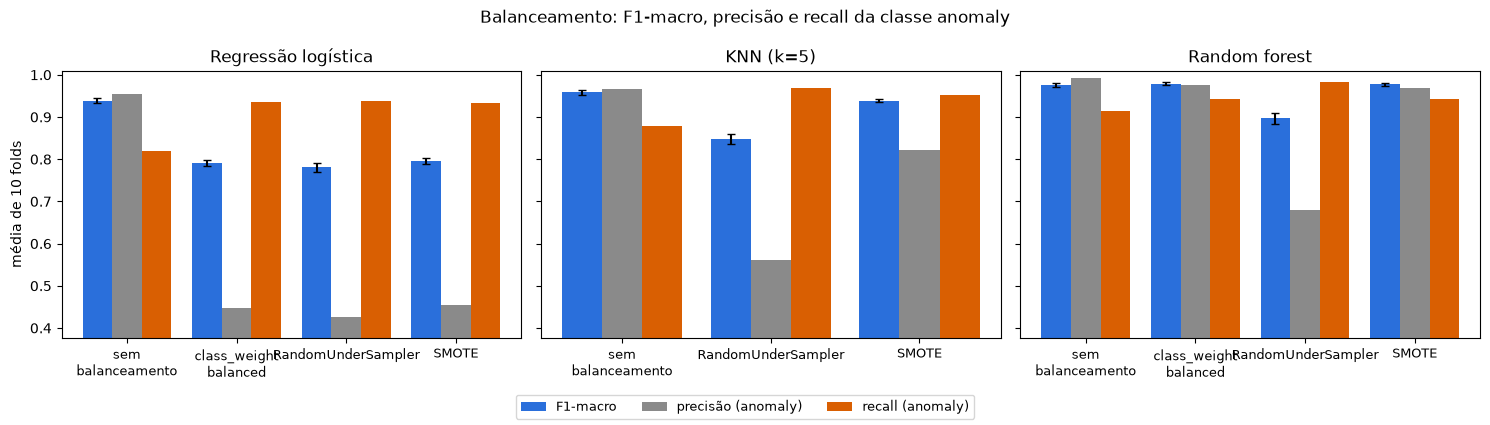

In [43]:
# gráfico 5: F1-macro, precisão e recall da classe anomaly, por modelo
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
metricas = {"F1-macro": ("f1_macro", AZUL), "precisão (anomaly)": ("precisao", CINZA), "recall (anomaly)": ("recall", LARANJA)}
for ax, nome_m in zip(axes, MODELOS_P4):
    s = bal_res[bal_res["modelo"] == nome_m].set_index("balanceamento")
    x = np.arange(len(s))
    for k, (rotulo, (col, cor)) in enumerate(metricas.items()):
        ax.bar(x + (k - 1) * 0.27, s[col], 0.27, color=cor, label=rotulo,
               yerr=s["desvio"] if col == "f1_macro" else None, capsize=3)
    ax.set_xticks(x)
    ax.set_xticklabels([b.replace(" ", "\n", 1) for b in s.index], fontsize=9)
    ax.set_title(nome_m)
axes[0].set_ylim(bal_res[["precisao", "recall"]].min().min() - 0.05, 1.01)
axes[0].set_ylabel("média de 10 folds")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=9)
fig.suptitle("Balanceamento: F1-macro, precisão e recall da classe anomaly")
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

**Conclusão da seção 1**

- **Conferência:** sem balanceamento deu 0,9387 na logística, 0,9588 no KNN e 0,9751 na random forest, os números da Pessoa 3. A diferença de 0,0001 na logística (ela tinha 0,9386) vem da versão das bibliotecas: rodei com scikit-learn 1.9.1 e imbalanced-learn 0.14.2.
- **Na regressão logística, as três técnicas derrubam o F1-macro de 0,9387 para 0,78–0,79**, perdendo nos 10 folds. O recall das anomalias sobe de 0,82 para 0,93–0,94, mas a precisão cai de 0,95 para 0,43–0,45: o modelo passa a chamar muita conexão normal de anomalia. Como as normais são 97% da base, basta errar uns 4% delas (cerca de 420 das 10.652 de um fold de validação) para os falsos alarmes passarem das anomalias verdadeiras (363).
- **No KNN acontece o mesmo, em escala menor:** o SMOTE perde 0,0200 (precisão de 0,97 para 0,82) e o `RandomUnderSampler` perde 0,1100.
- **O `RandomUnderSampler` é o pior nos três modelos.** Para empatar as classes, ele deixa só cerca de 2.900 linhas no treino de cada fold, contra 44 mil. Até a random forest cai para 0,8973 (precisão de 0,68).
- **A random forest é a única que ganha com o balanceamento:** com `class_weight="balanced"` vai a **0,9793 (+0,0042, ganhou nos 10 folds)**, e com SMOTE a 0,9773 (+0,0022, 7 de 10). O recall sobe de 0,915 para 0,944 e a precisão cai pouco (de 0,992 para 0,977). Nos outros modelos, a precisão despencou.

**Escolha: sem balanceamento** no pipeline desta etapa. Pela regra do grupo, a técnica não pode piorar nenhum modelo, e as três pioram muito a logística. O pipeline da Etapa 2 fica igual ao da Pessoa 3.

**Para a Etapa 3:** o modelo ainda não foi escolhido, e **`class_weight` + random forest é a melhor combinação de toda a Etapa 2** (0,9793). Ela e SMOTE + random forest (0,9773) têm que entrar na comparação de modelos. Para isso basta `montar_pipeline("class_weight balanced", modelo)`. Duas ideias que não testei: balancear só em parte (o parâmetro `sampling_strategy`, por exemplo 1 anomalia para 4 normais, em vez de 1 para 1) e ajustar o limiar de decisão da logística, que provavelmente é o que derruba a precisão dela.

### 2. Pipeline integrado

Aqui junto as quatro partes num pipeline só, partindo dos arquivos **originais**: `limpar()` da Pessoa 1 → pré-processamento das Pessoas 2 e 3 → balanceamento escolhido → modelo. Ajusto no treino inteiro, aplico no teste e confiro que nada quebra.

O modelo usado aqui é o de maior F1-macro com o balanceamento escolhido (a random forest), só para conferir que as peças se encaixam. **A escolha do modelo é da Etapa 3**, e o arquivo de submissão é da Etapa 4.

In [44]:
f1_bal = bal_res[bal_res["balanceamento"] == BAL_ESCOLHIDO].set_index("modelo")["f1_macro"]
MODELO_FINAL = f1_bal.idxmax()

# Pessoa 1: limpeza a partir dos arquivos originais
treino_final = L.limpar(pd.read_csv(PASTA / "treino.csv"), eh_treino=True)
teste_final = L.limpar(pd.read_csv(PASTA / "teste_sem_rotulo.csv"), eh_treino=False)
X_final, y_final = T.separar(treino_final)
X_teste_final = teste_final[X_final.columns]

# Pessoas 2, 3 e 4: pré-processamento + balanceamento + modelo
pipe_final = montar_pipeline(BAL_ESCOLHIDO, MODELOS_P4[MODELO_FINAL]).fit(X_final, y_final)
previsto = pipe_final.predict(X_teste_final)

conferencias = {
    "limpar() nos originais dá o mesmo treino da comparação": X_final.shape == X.shape and bool((y_final.to_numpy() == y.to_numpy()).all()),
    "teste continua com 24.333 linhas": len(previsto) == 24333,
    "só previsões 0 ou 1": set(np.unique(previsto)) <= {0, 1},
    "teste com as mesmas colunas do treino (sem id)": list(X_teste_final.columns) == list(X_final.columns),
}
for nome, ok in conferencias.items():
    print("OK  " if ok else "ERRO", nome)
assert all(conferencias.values())

print(f"\nPipeline final: {BAL_ESCOLHIDO} + {MODELO_FINAL} (F1-macro na validação: {f1_bal[MODELO_FINAL]:.4f})")
print(" -> ".join(pipe_final.named_steps))
print(f"Anomalias previstas no teste: {previsto.mean() * 100:.2f}% (no treino: {y_final.mean() * 100:.2f}%)")

OK   limpar() nos originais dá o mesmo treino da comparação
OK   teste continua com 24.333 linhas
OK   só previsões 0 ou 1
OK   teste com as mesmas colunas do treino (sem id)

Pipeline final: sem balanceamento + Random forest (F1-macro na validação: 0.9751)
pre -> balancear -> modelo
Anomalias previstas no teste: 4.62% (no treino: 3.30%)


### 3. Tabela comparativa geral

O F1-macro de cada etapa, acumulando as escolhas de cada pessoa. Todas as linhas usam os mesmos 10 folds, então dá para comparar uma com a outra. Os números saem das variáveis das seções anteriores (`res_imp` da Pessoa 2, `comp` da Pessoa 3 e `bal_res` daqui), então esta célula só roda depois do notebook inteiro.

A Pessoa 2 não rodou o KNN, então a primeira linha não tem esse modelo. A linha do modelo base da Pessoa 1, com e sem `score_ids_legado`, entra quando a `avaliar()` dela sair.

In [45]:
def f1_txt(media, desvio):
    return f"{media:.4f} ± {desvio:.4f}"

etapas = {}
r = res_imp[res_imp["técnica"] == "mediana (referência)"].set_index("modelo")
etapas["Pessoa 2: mediana + moda + one-hot (referência)"] = {m: f1_txt(r.loc[m, "F1-macro"], r.loc[m, "desvio"]) for m in r.index}
for nome, tec in [("Pessoa 2: + one-hot com raras juntas", "sem log1p | StandardScaler"),
                  ("Pessoa 3: + log1p nas contagens", "log1p todas as contagens | StandardScaler")]:
    r = comp[comp["técnica"] == tec].set_index("modelo")
    etapas[nome] = {m: f1_txt(r.loc[m, "f1_macro"], r.loc[m, "desvio"]) for m in r.index}
r = bal_res[bal_res["balanceamento"] == BAL_ESCOLHIDO].set_index("modelo")
etapas[f"Pessoa 4: + {BAL_ESCOLHIDO}"] = {m: f1_txt(r.loc[m, "f1_macro"], r.loc[m, "desvio"]) for m in r.index}

tabela_geral = pd.DataFrame(etapas).T.reindex(columns=list(MODELOS_P4)).fillna("—")
tabela_geral.index.name = "etapa (acumulando as anteriores)"
display(tabela_geral)

,Regressão logística,KNN (k=5),Random forest
etapa (acumulando as anteriores),,,
Pessoa 2: mediana + moda + one-hot (referência),0.9302 ± 0.0053,—,0.9728 ± 0.0043
Pessoa 2: + one-hot com raras juntas,0.9308 ± 0.0057,0.9508 ± 0.0061,0.9750 ± 0.0041
Pessoa 3: + log1p nas contagens,0.9387 ± 0.0053,0.9588 ± 0.0061,0.9751 ± 0.0043
Pessoa 4: + sem balanceamento,0.9387 ± 0.0053,0.9588 ± 0.0061,0.9751 ± 0.0043


**Conclusão da Etapa 2**

| Parte | Técnicas comparadas | Escolha |
|---|---|---|
| Pessoa 1: redundantes e inconsistentes | padronizar texto, valores impossíveis → ausentes, duplicatas, linhas contraditórias, colunas copiadas, constante e de vazamento | `limpar()`: todas as regras |
| Pessoa 2: ausentes e codificação | mediana, média, indicadores, iterativa, categoria "ausente"; one-hot, one-hot com raras, frequência, alvo, ordinal | mediana + moda + one-hot com os serviços raros juntos |
| Pessoa 3: transformação e redução | `log1p` (bytes ou todas as contagens) × sem escala, `StandardScaler`, `RobustScaler`; PCA em todas as colunas ou só nas numéricas | `log1p` nas contagens + `StandardScaler`, sem PCA |
| Pessoa 4: balanceamento | `class_weight`, `RandomUnderSampler`, SMOTE | sem balanceamento (`class_weight` + random forest fica para a Etapa 3) |

Somando as escolhas, o F1-macro na validação cruzada foi de 0,9302 para 0,9387 na logística e de 0,9728 para 0,9751 na random forest. O KNN, que entrou na Pessoa 3, foi de 0,9508 para 0,9588. O notebook roda do início ao fim, e o pipeline integrado vai dos arquivos originais até a previsão do teste sem erro. Todo o ajuste (imputação, codificação, escala e balanceamento) acontece só no treino de cada fold.

O pipeline prevê 4,62% de anomalias no teste, contra 3,30% no treino. Sem o gabarito não dá para saber se o teste tem mais anomalias ou se o modelo erra mais lá.

**Ainda em aberto:**
- a `avaliar()` oficial e o modelo base com e sem `score_ids_legado` (Pessoa 1). A linha dela entra na tabela geral quando sair;
- a decisão sobre `score_ids_legado`, que o enunciado pede para justificar como possível vazamento.